In [3]:
import numpy as np
import pandas as pd
import random
import time

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

print("GOA-GA workspace ready!")

GOA-GA workspace ready!


In [4]:
# Check that our training and testing datasets are available

print("Training data:", X_group_train_scaled.shape)
print("Testing data:", X_group_test_scaled.shape)

print("Training labels:", y_group_train.shape)
print("Testing labels:", y_group_test.shape)

NameError: name 'X_group_train_scaled' is not defined

In [ ]:
import joblib

# Load previously prepared datasets
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

# Restore the variables
X_group_train_scaled = prepared_data["X_group_train_scaled"]
X_group_test_scaled = prepared_data["X_group_test_scaled"]

y_group_train = prepared_data["y_group_train"]
y_group_test = prepared_data["y_group_test"]

label_encoder = prepared_data["label_encoder"]
group_scaler = prepared_data["group_scaler"]

print("Prepared datasets loaded successfully!")

Prepared datasets loaded successfully!


In [ ]:
print("Training data:", X_group_train_scaled.shape)
print("Testing data:", X_group_test_scaled.shape)

print("Training labels:", y_group_train.shape)
print("Testing labels:", y_group_test.shape)

Training data: (291855, 17)
Testing data: (73933, 17)
Training labels: (291855,)
Testing labels: (73933,)


In [ ]:
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

feature_names = prepared_data["feature_names"]
train_groups = prepared_data["train_groups"]

print("Number of features:", len(feature_names))
print("\nFeature names:")
print(feature_names)

print("\nTraining node IDs:", len(train_groups))

Number of features: 17

Feature names:
['Time', 'Is_CH', 'who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'DATA_R', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy']

Training node IDs: 291855


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

validation_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

subtrain_idx, val_idx = next(
    validation_split.split(
        X_group_train_scaled,
        y_group_train,
        groups=train_groups
    )
)

X_subtrain = X_group_train_scaled[subtrain_idx]
X_val = X_group_train_scaled[val_idx]

y_subtrain = y_group_train[subtrain_idx]
y_val = y_group_train[val_idx]

print("Sub-training data:", X_subtrain.shape)
print("Validation data:", X_val.shape)
print("Sub-training labels:", y_subtrain.shape)
print("Validation labels:", y_val.shape)

Sub-training data: (231744, 17)
Validation data: (60111, 17)
Sub-training labels: (231744,)
Validation labels: (60111,)


In [ ]:
subtrain_nodes = set(train_groups[subtrain_idx])
validation_nodes = set(train_groups[val_idx])

print(
    "Common nodes:",
    len(subtrain_nodes.intersection(validation_nodes))
)

Common nodes: 0


In [ ]:
import numpy as np

# Set a fixed random seed
rng = np.random.default_rng(42)

# Sample training and validation records
train_sample_size = min(5000, len(X_subtrain))
val_sample_size = min(1500, len(X_val))

train_sample_idx = rng.choice(
    len(X_subtrain),
    size=train_sample_size,
    replace=False
)

val_sample_idx = rng.choice(
    len(X_val),
    size=val_sample_size,
    replace=False
)

X_fitness_train = X_subtrain[train_sample_idx]
X_fitness_val = X_val[val_sample_idx]

y_fitness_train = y_subtrain[train_sample_idx]
y_fitness_val = y_val[val_sample_idx]

print("Fitness training sample:", X_fitness_train.shape)
print("Fitness validation sample:", X_fitness_val.shape)

Fitness training sample: (5000, 17)
Fitness validation sample: (1500, 17)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

def fitness_function(solution):

    # Identify selected features
    selected_features = np.where(solution == 1)[0]

    # Reject solutions with no selected features
    if len(selected_features) == 0:
        return 0

    # Select only the chosen features
    X_train_selected = X_fitness_train[:, selected_features]
    X_val_selected = X_fitness_val[:, selected_features]

    # Create KNN classifier
    model = KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean",
        n_jobs=-1
    )

    # Train the model
    model.fit(X_train_selected, y_fitness_train)

    # Predict validation labels
    predictions = model.predict(X_val_selected)

    # Calculate macro F1-score
    score = f1_score(
        y_fitness_val,
        predictions,
        average="macro",
        zero_division=0
    )

    # Calculate feature penalty
    feature_penalty = 0.01 * (
        len(selected_features) / len(feature_names)
    )

    # Final fitness
    fitness = score - feature_penalty

    return fitness

In [ ]:
all_features = np.ones(17, dtype=int)

all_feature_fitness = fitness_function(all_features)

print("Fitness using all features:", all_feature_fitness)

Fitness using all features: 0.8751305860527813


In [ ]:
four_features = np.array([
    1, 1, 0, 0, 1, 0, 0, 1, 0,
    0, 0, 0, 0, 0, 0, 0
])

four_feature_fitness = fitness_function(four_features)

print("Fitness using four features:", four_feature_fitness)

Fitness using four features: 0.6107692321564233


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Select 5,000 training records with class proportions preserved
train_indices, _ = train_test_split(
    np.arange(len(y_subtrain)),
    train_size=5000,
    random_state=42,
    stratify=y_subtrain
)

# Select 1,500 validation records with class proportions preserved
val_indices, _ = train_test_split(
    np.arange(len(y_val)),
    train_size=1500,
    random_state=42,
    stratify=y_val
)

# Create the fitness datasets
X_fitness_train = X_subtrain[train_indices]
X_fitness_val = X_val[val_indices]

y_fitness_train = y_subtrain[train_indices]
y_fitness_val = y_val[val_indices]

print("Training sample:", X_fitness_train.shape)
print("Validation sample:", X_fitness_val.shape)

print("\nTraining class distribution:")
print(np.unique(y_fitness_train, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_fitness_val, return_counts=True))

Training sample: (5000, 17)
Validation sample: (1500, 17)

Training class distribution:
(array([0, 1, 2, 3, 4]), array([ 137,   43,  192, 4537,   91]))

Validation class distribution:
(array([0, 1, 2, 3, 4]), array([  41,   12,   56, 1365,   26]))


In [ ]:
# Test using all 17 features
all_features = np.ones(17, dtype=int)
all_feature_fitness = fitness_function(all_features)

# Test using four features
four_features = np.array([
    1, 1, 0, 0, 1, 0, 0, 1, 0,
    0, 0, 0, 0, 0, 0, 0, 0
])
four_feature_fitness = fitness_function(four_features)

print("Fitness using all 17 features:", all_feature_fitness)
print("Fitness using four features:", four_feature_fitness)

Fitness using all 17 features: 0.8367510160263784
Fitness using four features: 0.6464832600716547


In [ ]:
import numpy as np

# Reproducible random population
np.random.seed(42)

# GOA-GA initial settings
population_size = 10
number_of_features = len(feature_names)
max_iterations = 5

# Generate initial binary population
population = np.random.randint(
    0, 2,
    size=(population_size, number_of_features)
)

# Ensure every solution selects at least one feature
for i in range(population_size):
    if np.sum(population[i]) == 0:
        random_feature = np.random.randint(0, number_of_features)
        population[i, random_feature] = 1

print("Population shape:", population.shape)
print("\nInitial population:")
print(population)

print("\nNumber of selected features in each solution:")
print(np.sum(population, axis=1))

Population shape: (10, 17)

Initial population:
[[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1]
 [1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1]
 [1 0 1 0 0 0 0 0 1 1 1 1 1 0 1 1 0]
 [1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 0]
 [1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0]
 [0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1]
 [1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1]
 [0 1 0 1 0 0 1 1 0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 1 1 1 0 0 0 0 1 0 0 0]
 [0 0 1 0 1 0 1 0 0 1 1 1 0 1 0 0 1]]

Number of selected features in each solution:
[ 5 13  9  6 11 13 13  7  5  8]


In [ ]:
# Store fitness scores for all candidates
fitness_scores = []

for i in range(population_size):
    score = fitness_function(population[i])
    fitness_scores.append(score)

    print(
        f"Candidate {i + 1}: "
        f"Selected features = {np.sum(population[i])}, "
        f"Fitness = {score:.6f}"
    )

# Find the best candidate
best_index = np.argmax(fitness_scores)

best_solution = population[best_index].copy()
best_fitness = fitness_scores[best_index]

print("\nBest candidate:", best_index + 1)
print("Best fitness:", best_fitness)
print("Selected feature count:", np.sum(best_solution))

Candidate 1: Selected features = 5, Fitness = 0.795468
Candidate 2: Selected features = 13, Fitness = 0.777357
Candidate 3: Selected features = 9, Fitness = 0.766949
Candidate 4: Selected features = 6, Fitness = 0.736995
Candidate 5: Selected features = 11, Fitness = 0.826017
Candidate 6: Selected features = 13, Fitness = 0.911095
Candidate 7: Selected features = 13, Fitness = 0.780377
Candidate 8: Selected features = 7, Fitness = 0.496746
Candidate 9: Selected features = 5, Fitness = 0.847715
Candidate 10: Selected features = 8, Fitness = 0.764668

Best candidate: 6
Best fitness: 0.9110950506240602
Selected feature count: 13


In [ ]:
import numpy as np

# GOA parameters
c_max = 1
c_min = 0.00004

population_size = 10
number_of_features = 17
max_iterations = 5

# Convert binary population into continuous positions
positions = population.astype(float)

# GOA social interaction parameters
f = 0.5
l = 1.5

# Keep track of the best solution
best_solution = population[best_index].copy()
best_fitness = fitness_scores[best_index]

# Store best fitness in each iteration
goa_history = []

for iteration in range(max_iterations):

    # Decrease the comfort-zone coefficient
    c = c_max - iteration * ((c_max - c_min) / max_iterations)

    new_positions = positions.copy()

    for i in range(population_size):

        social_force = np.zeros(number_of_features)

        for j in range(population_size):

            if i != j:

                distance = np.linalg.norm(positions[j] - positions[i])

                if distance > 0:

                    direction = (
                        positions[j] - positions[i]
                    ) / distance

                    s = f * np.exp(-distance / l) - np.exp(-distance)

                    social_force += (
                        c * (1.0 / 2) * s * direction
                    )

        # Move grasshopper towards social influence
        new_positions[i] = (
            c * social_force + best_solution
        )

    # Restrict positions between 0 and 1
    positions = np.clip(new_positions, 0, 1)

    # Convert continuous positions into binary solutions
    probabilities = 1 / (1 + np.exp(-10 * (positions - 0.5)))

    new_population = (
        np.random.random(positions.shape) < probabilities
    ).astype(int)

    # Ensure no candidate is empty
    for i in range(population_size):
        if np.sum(new_population[i]) == 0:
            random_feature = np.random.randint(number_of_features)
            new_population[i, random_feature] = 1

    # Preserve the current best solution (elitism)
    new_population[0] = best_solution

    population = new_population

    # Evaluate new population
    current_scores = [
        fitness_function(solution) for solution in population
    ]

    # Update global best
    current_best_index = np.argmax(current_scores)

    if current_scores[current_best_index] > best_fitness:
        best_fitness = current_scores[current_best_index]
        best_solution = population[current_best_index].copy()

    goa_history.append(best_fitness)

    print(
        f"Iteration {iteration + 1}: "
        f"Best fitness = {best_fitness:.6f}, "
        f"Selected features = {np.sum(best_solution)}"
    )

print("\nGOA completed!")
print("Best GOA fitness:", best_fitness)
print("Selected features:", np.sum(best_solution))

Iteration 1: Best fitness = 0.911095, Selected features = 13
Iteration 2: Best fitness = 0.911095, Selected features = 13
Iteration 3: Best fitness = 0.911095, Selected features = 13
Iteration 4: Best fitness = 0.911095, Selected features = 13
Iteration 5: Best fitness = 0.911095, Selected features = 13

GOA completed!
Best GOA fitness: 0.9110950506240602
Selected features: 13


In [ ]:
import numpy as np

# GA parameters
crossover_probability = 0.8
mutation_probability = 0.1

# Create a new population
new_population = []

# Preserve the best solution (elitism)
new_population.append(best_solution.copy())

while len(new_population) < population_size:

    # Select two parents randomly
    parent_indices = np.random.choice(
        population_size, size=2, replace=False
    )

    parent1 = population[parent_indices[0]].copy()
    parent2 = population[parent_indices[1]].copy()

    child1 = parent1.copy()
    child2 = parent2.copy()

    # Single-point crossover
    if np.random.random() < crossover_probability:

        crossover_point = np.random.randint(
            1, number_of_features
        )

        child1 = np.concatenate((
            parent1[:crossover_point],
            parent2[crossover_point:]
        ))

        child2 = np.concatenate((
            parent2[:crossover_point],
            parent1[crossover_point:]
        ))

    # Mutation
    for child in [child1, child2]:

        for feature in range(number_of_features):

            if np.random.random() < mutation_probability:
                child[feature] = 1 - child[feature]

        # Ensure at least one feature is selected
        if np.sum(child) == 0:
            random_feature = np.random.randint(number_of_features)
            child[random_feature] = 1

        if len(new_population) < population_size:
            new_population.append(child.copy())

# Update population
population = np.array(new_population)

print("New GA population shape:", population.shape)
print("\nNew population:")
print(population)

print("\nSelected features in each candidate:")
print(np.sum(population, axis=1))

New GA population shape: (10, 17)

New population:
[[0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1]
 [0 1 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1]
 [0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1]
 [0 0 0 1 1 1 1 1 1 1 1 1 1 0 0 0 1]
 [0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1]
 [0 1 0 1 1 1 1 0 1 1 1 0 1 1 0 1 1]
 [0 1 0 1 1 1 1 0 1 0 1 1 1 1 0 0 1]
 [0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 0 1]
 [0 1 0 1 1 1 0 1 1 1 1 1 0 1 1 0 1]
 [0 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0]]

Selected features in each candidate:
[13 13 13 11 14 12 11 11 12 12]


In [ ]:
# Evaluate all candidates in the GA population
ga_fitness_scores = []

for i in range(population_size):

    score = fitness_function(population[i])
    ga_fitness_scores.append(score)

    print(
        f"Candidate {i + 1}: "
        f"Selected features = {np.sum(population[i])}, "
        f"Fitness = {score:.6f}"
    )

# Find the best candidate in the GA population
ga_best_index = np.argmax(ga_fitness_scores)

ga_best_solution = population[ga_best_index].copy()
ga_best_fitness = ga_fitness_scores[ga_best_index]

# Compare GA result with the previous GOA result
if ga_best_fitness > best_fitness:

    best_fitness = ga_best_fitness
    best_solution = ga_best_solution.copy()

print("\n========== GA RESULTS ==========")

print("Best GA candidate:", ga_best_index + 1)
print("Best GA fitness:", ga_best_fitness)

print("\n========== HYBRID BEST RESULT ==========")

print("Best hybrid fitness:", best_fitness)
print("Selected features:", np.sum(best_solution))

Candidate 1: Selected features = 13, Fitness = 0.911095
Candidate 2: Selected features = 13, Fitness = 0.911095
Candidate 3: Selected features = 13, Fitness = 0.911398
Candidate 4: Selected features = 11, Fitness = 0.889318
Candidate 5: Selected features = 14, Fitness = 0.899504
Candidate 6: Selected features = 12, Fitness = 0.915902
Candidate 7: Selected features = 11, Fitness = 0.902713
Candidate 8: Selected features = 11, Fitness = 0.898798
Candidate 9: Selected features = 12, Fitness = 0.897349
Candidate 10: Selected features = 12, Fitness = 0.816334

========== GA RESULTS ==========
Best GA candidate: 6
Best GA fitness: 0.9159017765411628

========== HYBRID BEST RESULT ==========
Best hybrid fitness: 0.9159017765411628
Selected features: 12


In [ ]:
# Get the indexes of selected features
selected_indices = np.where(best_solution == 1)[0]

# Convert indexes into feature names
selected_feature_names = [
    feature_names[i] for i in selected_indices
]

print("Best fitness:", best_fitness)

print("\nNumber of selected features:", len(selected_feature_names))

print("\nSelected features:")
for i, feature in enumerate(selected_feature_names, start=1):
    print(f"{i}. {feature}")

Best fitness: 0.9159017765411628

Number of selected features: 12

Selected features:
1. Is_CH
2. Dist_To_CH
3. ADV_S
4. ADV_R
5. JOIN_S
6. SCH_S
7. SCH_R
8. Rank
9. DATA_R
10. Data_Sent_To_BS
11. send_code
12. Expaned Energy


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)
import time

# Find selected feature positions
selected_indices = np.where(best_solution == 1)[0]

# Prepare training and test data
X_train_selected = X_group_train_scaled[:, selected_indices]
X_test_selected = X_group_test_scaled[:, selected_indices]

# Create KNN model
final_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    n_jobs=-1
)

# Train the model
start_time = time.time()
final_knn.fit(X_train_selected, y_group_train)
training_time = time.time() - start_time

# Predict test data
start_time = time.time()
y_final_pred = final_knn.predict(X_test_selected)
prediction_time = time.time() - start_time

# Calculate evaluation metrics
accuracy = accuracy_score(y_group_test, y_final_pred)
precision = precision_score(
    y_group_test, y_final_pred,
    average="macro", zero_division=0
)
recall = recall_score(
    y_group_test, y_final_pred,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_group_test, y_final_pred,
    average="macro", zero_division=0
)

print("========== FINAL KNN RESULTS ==========")
print(f"Accuracy: {accuracy:.6f}")
print(f"Macro Precision: {precision:.6f}")
print(f"Macro Recall: {recall:.6f}")
print(f"Macro F1-score: {macro_f1:.6f}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Prediction time: {prediction_time:.2f} seconds")

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_group_test,
    y_final_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_group_test, y_final_pred))

========== FINAL KNN RESULTS ==========
Accuracy: 0.994928
Macro Precision: 0.969671
Macro Recall: 0.968337
Macro F1-score: 0.968661
Training time: 3.41 seconds
Prediction time: 12.40 seconds

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

   Blackhole       0.97      0.98      0.97      2089
    Flooding       0.93      0.98      0.96       671
    Grayhole       0.97      0.97      0.97      2781
      Normal       1.00      1.00      1.00     67029
        TDMA       0.98      0.92      0.95      1363

    accuracy                           0.99     73933
   macro avg       0.97      0.97      0.97     73933
weighted avg       0.99      0.99      0.99     73933


========== CONFUSION MATRIX ==========
[[ 2042     0    43     4     0]
 [    0   656     1    14     0]
 [   67     0  2701    13     0]
 [    4    46    50 66909    20]
 [    0     0     3   110  1250]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predictions from the original 17-feature model
baseline_predictions = group_knn.predict(X_group_test_scaled)

# Baseline metrics
baseline_accuracy = accuracy_score(
    y_group_test, baseline_predictions
)

baseline_precision = precision_score(
    y_group_test, baseline_predictions,
    average="macro", zero_division=0
)

baseline_recall = recall_score(
    y_group_test, baseline_predictions,
    average="macro", zero_division=0
)

baseline_f1 = f1_score(
    y_group_test, baseline_predictions,
    average="macro", zero_division=0
)

# Compare both models
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "17 Features": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ],
    "12 Selected Features": [
        accuracy,
        precision,
        recall,
        macro_f1
    ]
})

print(comparison.to_string(index=False))

NameError: name 'group_knn' is not defined

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create the original KNN model using all 17 features
group_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    n_jobs=-1
)

# Train using all 17 features
group_knn.fit(
    X_group_train_scaled,
    y_group_train
)

# Predict using the same node-wise test set
baseline_predictions = group_knn.predict(
    X_group_test_scaled
)

print("17-feature baseline model recreated successfully!")
print("Predictions:", len(baseline_predictions))

17-feature baseline model recreated successfully!
Predictions: 73933


In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "17 Features": [
        accuracy_score(y_group_test, baseline_predictions),
        precision_score(y_group_test, baseline_predictions,
                        average="macro", zero_division=0),
        recall_score(y_group_test, baseline_predictions,
                     average="macro", zero_division=0),
        f1_score(y_group_test, baseline_predictions,
                 average="macro", zero_division=0)
    ],
    "12 Selected Features": [
        accuracy,
        precision,
        recall,
        macro_f1
    ]
})

print(comparison.to_string(index=False))

         Metric  17 Features  12 Selected Features
       Accuracy     0.995374              0.994928
Macro Precision     0.974660              0.969671
   Macro Recall     0.969009              0.968337
 Macro F1-score     0.971467              0.968661


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# Classification report for original model
baseline_report = classification_report(
    y_group_test,
    baseline_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

# Classification report for selected-feature model
selected_report = classification_report(
    y_group_test,
    y_final_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

# Compare per-class recall
class_comparison = pd.DataFrame({
    "Class": label_encoder.classes_,
    "17 Feature Recall": [
        baseline_report[c]["recall"]
        for c in label_encoder.classes_
    ],
    "12 Feature Recall": [
        selected_report[c]["recall"]
        for c in label_encoder.classes_
    ]
})

print(class_comparison.to_string(index=False))

    Class  17 Feature Recall  12 Feature Recall
Blackhole           0.986596           0.977501
 Flooding           0.973174           0.977645
 Grayhole           0.964401           0.971233
   Normal           0.998642           0.998210
     TDMA           0.922230           0.917095


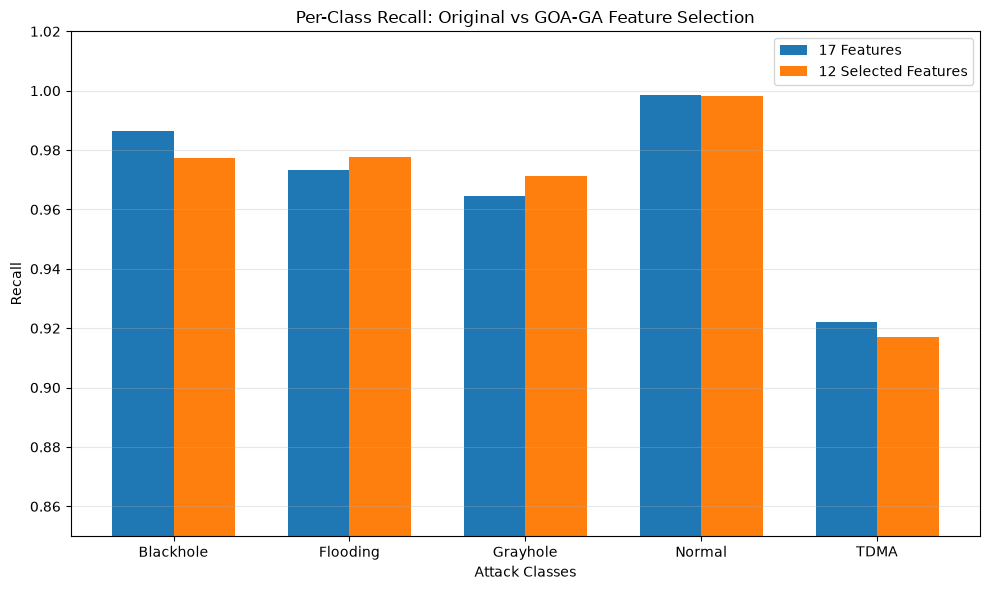

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

classes = label_encoder.classes_

recall_17 = class_comparison["17 Feature Recall"].values
recall_12 = class_comparison["12 Feature Recall"].values

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    recall_17,
    width,
    label="17 Features"
)

plt.bar(
    x + width/2,
    recall_12,
    width,
    label="12 Selected Features"
)

plt.xlabel("Attack Classes")
plt.ylabel("Recall")
plt.title("Per-Class Recall: Original vs GOA-GA Feature Selection")

plt.xticks(x, classes)
plt.ylim(0.85, 1.02)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
plt.savefig(
    "../results/per_class_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [ ]:
import joblib

# Load previously saved prepared data
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

# Restore variables
X_group_train_scaled = prepared_data["X_group_train_scaled"]
X_group_test_scaled = prepared_data["X_group_test_scaled"]

y_group_train = prepared_data["y_group_train"]
y_group_test = prepared_data["y_group_test"]

label_encoder = prepared_data["label_encoder"]
group_scaler = prepared_data["group_scaler"]

feature_names = prepared_data["feature_names"]
train_groups = prepared_data["train_groups"]

print("Prepared data loaded successfully!")
print("Training data:", X_group_train_scaled.shape)
print("Testing data:", X_group_test_scaled.shape)
print("Number of features:", len(feature_names))

Prepared data loaded successfully!
Training data: (291855, 17)
Testing data: (73933, 17)
Number of features: 17


In [ ]:
print("Feature names:")

for i, name in enumerate(feature_names):
    print(i, ":", name)

print("\nTarget classes:")
print(label_encoder.classes_)

Feature names:
0 : Time
1 : Is_CH
2 : who CH
3 : Dist_To_CH
4 : ADV_S
5 : ADV_R
6 : JOIN_S
7 : JOIN_R
8 : SCH_S
9 : SCH_R
10 : Rank
11 : DATA_S
12 : DATA_R
13 : Data_Sent_To_BS
14 : dist_CH_To_BS
15 : send_code
16 : Expaned Energy

Target classes:
['Blackhole' 'Flooding' 'Grayhole' 'Normal' 'TDMA']


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Split the training data by node ID
validation_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

subtrain_idx, val_idx = next(
    validation_split.split(
        X_group_train_scaled,
        y_group_train,
        groups=train_groups
    )
)

X_subtrain = X_group_train_scaled[subtrain_idx]
X_val = X_group_train_scaled[val_idx]

y_subtrain = y_group_train[subtrain_idx]
y_val = y_group_train[val_idx]

subtrain_groups = train_groups[subtrain_idx]
val_groups = train_groups[val_idx]

print("Subtraining data:", X_subtrain.shape)
print("Validation data:", X_val.shape)

print(
    "Overlapping groups:",
    len(set(subtrain_groups) & set(val_groups))
)

Subtraining data: (231744, 17)
Validation data: (60111, 17)
Overlapping groups: 0


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

train_indices, _ = train_test_split(
    np.arange(len(y_subtrain)),
    train_size=5000,
    random_state=42,
    stratify=y_subtrain
)

val_indices, _ = train_test_split(
    np.arange(len(y_val)),
    train_size=1500,
    random_state=42,
    stratify=y_val
)

X_fitness_train = X_subtrain[train_indices]
X_fitness_val = X_val[val_indices]

y_fitness_train = y_subtrain[train_indices]
y_fitness_val = y_val[val_indices]

print("Fitness training:", X_fitness_train.shape)
print("Fitness validation:", X_fitness_val.shape)

Fitness training: (5000, 17)
Fitness validation: (1500, 17)


In [ ]:
print("Training class distribution:")
print(np.unique(y_fitness_train, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_fitness_val, return_counts=True))

Training class distribution:
(array([0, 1, 2, 3, 4]), array([ 137,   43,  192, 4537,   91]))

Validation class distribution:
(array([0, 1, 2, 3, 4]), array([  41,   12,   56, 1365,   26]))


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

def fitness_function(solution):

    # Find the selected feature positions
    selected_features = np.where(solution == 1)[0]

    # If no feature is selected, return maximum error
    if len(selected_features) == 0:
        return 1.0

    # Select only the chosen features
    X_train_selected = X_fitness_train[:, selected_features]
    X_val_selected = X_fitness_val[:, selected_features]

    # Create and train the CART classifier
    model = DecisionTreeClassifier(random_state=42)

    model.fit(X_train_selected, y_fitness_train)

    # Predict validation labels
    predictions = model.predict(X_val_selected)

    # Calculate classification error
    accuracy = accuracy_score(y_fitness_val, predictions)
    error = 1 - accuracy

    return error

In [ ]:
# Select all 17 features for testing
all_features = np.ones(len(feature_names), dtype=int)

# Calculate CART classification error
all_features_error = fitness_function(all_features)

print("CART classification error:", all_features_error)
print("CART accuracy:", 1 - all_features_error)

CART classification error: 0.01200000000000001
CART accuracy: 0.988


In [ ]:
import numpy as np

# Set population size
population_size = 10

# Number of available features
number_of_features = len(feature_names)

# Fix random seed for reproducibility
np.random.seed(42)

# Generate random binary population
population = np.random.randint(
    0, 2,
    size=(population_size, number_of_features)
)

# Make sure every agent selects at least one feature
for i in range(population_size):
    if np.sum(population[i]) == 0:
        random_feature = np.random.randint(0, number_of_features)
        population[i, random_feature] = 1

print("Initial population shape:", population.shape)
print("\nInitial population:")
print(population)

print("\nNumber of selected features in each agent:")
print(np.sum(population, axis=1))

Initial population shape: (10, 17)

Initial population:
[[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1]
 [1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1]
 [1 0 1 0 0 0 0 0 1 1 1 1 1 0 1 1 0]
 [1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1 0]
 [1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0]
 [0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1]
 [1 1 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1]
 [0 1 0 1 0 0 1 1 0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 1 1 1 0 0 0 0 1 0 0 0]
 [0 0 1 0 1 0 1 0 0 1 1 1 0 1 0 0 1]]

Number of selected features in each agent:
[ 5 13  9  6 11 13 13  7  5  8]


In [ ]:
# Store the fitness value of every agent
fitness_values = []

for i in range(population_size):

    # Get the current agent
    solution = population[i]

    # Calculate its CART classification error
    error = fitness_function(solution)

    # Store the error
    fitness_values.append(error)

    print(
        f"Agent {i + 1}: "
        f"Selected features = {np.sum(solution)}, "
        f"CART error = {error:.4f}"
    )

# Convert the list into a NumPy array
fitness_values = np.array(fitness_values)

# Find the agent with minimum classification error
best_index = np.argmin(fitness_values)

best_solution = population[best_index].copy()
best_fitness = fitness_values[best_index]

print("\nBest initial agent:", best_index + 1)
print("Best classification error:", best_fitness)
print("Best CART accuracy:", 1 - best_fitness)
print("Number of selected features:", np.sum(best_solution))

Agent 1: Selected features = 5, CART error = 0.0287
Agent 2: Selected features = 13, CART error = 0.0220
Agent 3: Selected features = 9, CART error = 0.0473
Agent 4: Selected features = 6, CART error = 0.0480
Agent 5: Selected features = 11, CART error = 0.0247
Agent 6: Selected features = 13, CART error = 0.0113
Agent 7: Selected features = 13, CART error = 0.0120
Agent 8: Selected features = 7, CART error = 0.0780
Agent 9: Selected features = 5, CART error = 0.0247
Agent 10: Selected features = 8, CART error = 0.0240

Best initial agent: 6
Best classification error: 0.011333333333333306
Best CART accuracy: 0.9886666666666667
Number of selected features: 13


In [ ]:
import numpy as np

# GOA parameters
f = 0.5
l = 1.5

c_max = 1
c_min = 0.00004

max_iterations = 5

# Social interaction function from Equation 4
def social_function(distance):
    return f * np.exp(-distance / l) - np.exp(-distance)


# Comfort-zone coefficient from Equation 9
def calculate_c(iteration):
    return c_max - (
        iteration * (c_max - c_min) / max_iterations
    )


# Test the functions
print("Social interaction at distance 1:", social_function(1))
print("Comfort coefficient at iteration 1:", calculate_c(1))

Social interaction at distance 1: -0.11117088165514633
Comfort coefficient at iteration 1: 0.800008


In [ ]:
def sigmoid(position):
    return 1 / (1 + np.exp(-position))


def binary_conversion(position):
    probabilities = sigmoid(position)
    return (probabilities >= 0.5).astype(int)

In [ ]:
# Convert binary population into continuous positions

positions = np.where(population == 1, 1.0, -1.0)

print("Continuous positions shape:", positions.shape)
print("\nFirst agent's continuous position:")
print(positions[0])

# Convert continuous positions back into binary
binary_check = binary_conversion(positions)

print("\nFirst agent's binary position:")
print(binary_check[0])

Continuous positions shape: (10, 17)

First agent's continuous position:
[-1.  1. -1. -1. -1.  1. -1. -1. -1.  1. -1. -1. -1. -1.  1. -1.  1.]

First agent's binary position:
[0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1]


In [ ]:
# Find the best agent in the population

best_agent_index = np.argmin(fitness_values)

best_position = positions[best_agent_index].copy()
best_fitness = fitness_values[best_agent_index]

print("Best agent index:", best_agent_index)
print("Best fitness (classification error):", best_fitness)
print("Best position:")
print(best_position)

print("Number of selected features:",
      np.sum(binary_conversion(best_position)))

Best agent index: 5
Best fitness (classification error): 0.011333333333333306
Best position:
[-1.  1. -1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1. -1. -1.  1.]
Number of selected features: 13


In [ ]:
# Calculate Euclidean distances between all agents

distance_matrix = np.zeros((population_size, population_size))

for i in range(population_size):
    for j in range(population_size):
        distance_matrix[i, j] = np.linalg.norm(
            positions[i] - positions[j]
        )

print("Distance matrix shape:", distance_matrix.shape)
print("\nDistances from the first agent:")
print(distance_matrix[0])

print("\nDistance between best agent and first agent:")
print(distance_matrix[best_agent_index, 0])

Distance matrix shape: (10, 10)

Distances from the first agent:
[0.         6.32455532 6.32455532 5.29150262 6.32455532 6.32455532
 6.92820323 5.65685425 6.32455532 6.        ]

Distance between best agent and first agent:
6.324555320336759


In [ ]:
# Calculate social interaction between agents

social_matrix = np.zeros((population_size, population_size))

for i in range(population_size):
    for j in range(population_size):
        if i != j:
            social_matrix[i, j] = social_function(
                distance_matrix[i, j]
            )

print("Social interaction matrix shape:", social_matrix.shape)

print("\nSocial interactions of the first agent:")
print(social_matrix[0])

print("\nSocial interaction between best agent and first agent:")
print(social_matrix[best_agent_index, 0])

Social interaction matrix shape: (10, 10)

Social interactions of the first agent:
[0.         0.00558428 0.00558428 0.00965247 0.00558428 0.00558428
 0.00395254 0.0080183  0.00558428 0.00667907]

Social interaction between best agent and first agent:
0.005584284362389273


In [ ]:
# Calculate social interaction contribution

social_force = np.zeros((population_size, number_of_features))

for i in range(population_size):
    for j in range(population_size):
        if i != j:
            distance = distance_matrix[i, j]

            direction = (
                positions[j] - positions[i]
            ) / (distance + 1e-10)

            social_force[i] += (
                social_matrix[i, j] * direction
            )

print("Social force shape:", social_force.shape)

print("\nSocial force of the first agent:")
print(social_force[0])

Social force shape: (10, 17)

Social force of the first agent:
[ 0.01008701 -0.00940646  0.01054746  0.00927362  0.01054746 -0.00859307
  0.01149997  0.00989852  0.00997053 -0.0065552   0.01149997  0.01326588
  0.00529772  0.00866507 -0.01326588  0.01008701 -0.01178091]


In [ ]:
# Update positions using GOA

iteration = 1

c = calculate_c(iteration)

new_positions = np.zeros_like(positions)

for i in range(population_size):
    new_positions[i] = (
        c * social_force[i] + best_position
    )

print("Comfort coefficient:", c)

print("\nUpdated position of first agent:")
print(new_positions[0])

print("\nUpdated positions shape:", new_positions.shape)

Comfort coefficient: 0.800008

Updated position of first agent:
[-0.99193031  0.99247476 -0.99156195  1.00741897  1.00843805  0.99312548
  1.00920007  1.0079189   1.0079765   0.99475579  1.00920007  1.01061281
  1.00423822  1.00693213 -1.01061281 -0.99193031  0.99057518]

Updated positions shape: (10, 17)


In [ ]:
# Restrict updated positions to the range [-1, 1]

new_positions = np.clip(new_positions, -1, 1)

# Convert updated continuous positions into binary positions
new_population = binary_conversion(new_positions)

print("New population shape:", new_population.shape)

print("\nFirst agent's updated binary position:")
print(new_population[0])

print("\nNumber of features selected by each agent:")
print(np.sum(new_population, axis=1))

New population shape: (10, 17)

First agent's updated binary position:
[0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1]

Number of features selected by each agent:
[13 13 13 13 13 13 13 13 13 13]


In [ ]:
# Evaluate the updated population

new_fitness_values = []

for i in range(population_size):
    error = fitness_function(new_population[i])
    new_fitness_values.append(error)

new_fitness_values = np.array(new_fitness_values)

for i in range(population_size):
    print(
        f"Agent {i + 1}: "
        f"Features = {np.sum(new_population[i])}, "
        f"CART Error = {new_fitness_values[i]:.4f}"
    )

new_best_index = np.argmin(new_fitness_values)

print("\nBest updated agent:", new_best_index + 1)
print("Best updated error:", new_fitness_values[new_best_index])

Agent 1: Features = 13, CART Error = 0.0113
Agent 2: Features = 13, CART Error = 0.0113
Agent 3: Features = 13, CART Error = 0.0113
Agent 4: Features = 13, CART Error = 0.0113
Agent 5: Features = 13, CART Error = 0.0113
Agent 6: Features = 13, CART Error = 0.0113
Agent 7: Features = 13, CART Error = 0.0113
Agent 8: Features = 13, CART Error = 0.0113
Agent 9: Features = 13, CART Error = 0.0113
Agent 10: Features = 13, CART Error = 0.0113

Best updated agent: 1
Best updated error: 0.011333333333333306


In [ ]:
# Probabilistic binary conversion

def stochastic_binary_conversion(position):
    probabilities = sigmoid(position)

    random_values = np.random.random(len(position))

    binary_solution = (
        random_values < probabilities
    ).astype(int)

    # Ensure at least one feature is selected
    if np.sum(binary_solution) == 0:
        best_feature = np.argmax(probabilities)
        binary_solution[best_feature] = 1

    return binary_solution


# Generate a diverse population
np.random.seed(42)

new_population = np.array([
    stochastic_binary_conversion(new_positions[i])
    for i in range(population_size)
])

print("New population shape:", new_population.shape)

print("\nSelected features per agent:")
print(np.sum(new_population, axis=1))

print("\nFirst agent:")
print(new_population[0])

New population shape: (10, 17)

Selected features per agent:
[11 13 11 10 11 12  9 10 12 13]

First agent:
[0 0 0 1 1 1 1 0 1 1 1 0 0 1 1 1 1]


In [ ]:
# Evaluate the new stochastic population

stochastic_fitness_values = []

for i in range(population_size):
    error = fitness_function(new_population[i])
    stochastic_fitness_values.append(error)

stochastic_fitness_values = np.array(stochastic_fitness_values)

for i in range(population_size):
    print(
        f"Agent {i + 1}: "
        f"Features = {np.sum(new_population[i])}, "
        f"CART Error = {stochastic_fitness_values[i]:.4f}"
    )

best_stochastic_index = np.argmin(stochastic_fitness_values)

print("\nBest agent:", best_stochastic_index + 1)
print("Best CART error:", stochastic_fitness_values[best_stochastic_index])
print("Best accuracy:", 1 - stochastic_fitness_values[best_stochastic_index])


Agent 1: Features = 11, CART Error = 0.0120
Agent 2: Features = 13, CART Error = 0.0333
Agent 3: Features = 11, CART Error = 0.0273
Agent 4: Features = 10, CART Error = 0.0300
Agent 5: Features = 11, CART Error = 0.0207
Agent 6: Features = 12, CART Error = 0.0113
Agent 7: Features = 9, CART Error = 0.0580
Agent 8: Features = 10, CART Error = 0.0133
Agent 9: Features = 12, CART Error = 0.0147
Agent 10: Features = 13, CART Error = 0.0227

Best agent: 6
Best CART error: 0.011333333333333306
Best accuracy: 0.9886666666666667


In [ ]:
# GA: Tournament selection

def tournament_selection(population, fitness_values):
    selected_parents = []

    for _ in range(population_size):
        candidates = np.random.choice(
            population_size, size=2, replace=False
        )

        winner = candidates[
            np.argmin(fitness_values[candidates])
        ]

        selected_parents.append(population[winner])

    return np.array(selected_parents)


np.random.seed(42)

selected_parents = tournament_selection(
    new_population,
    stochastic_fitness_values
)

print("Selected parents shape:", selected_parents.shape)

print("\nNumber of selected features in each parent:")
print(np.sum(selected_parents, axis=1))

Selected parents shape: (10, 17)

Number of selected features in each parent:
[12 11 13 10 12 12 12 12 11 11]


In [ ]:
# GA: Single-point crossover

def crossover(parent1, parent2, crossover_rate=0.8):

    child1 = parent1.copy()
    child2 = parent2.copy()

    if np.random.random() < crossover_rate:

        crossover_point = np.random.randint(
            1, number_of_features
        )

        child1 = np.concatenate((
            parent1[:crossover_point],
            parent2[crossover_point:]
        ))

        child2 = np.concatenate((
            parent2[:crossover_point],
            parent1[crossover_point:]
        ))

    return child1, child2


# Generate children from selected parents

np.random.seed(42)

children = []

for i in range(0, population_size, 2):

    child1, child2 = crossover(
        selected_parents[i],
        selected_parents[i + 1]
    )

    children.extend([child1, child2])

children = np.array(children)

print("Children population shape:", children.shape)

print("\nSelected features in each child:")
print(np.sum(children, axis=1))

print("\nFirst child:")
print(children[0])

Children population shape: (10, 17)

Selected features in each child:
[13 10 11 12 13 11 13 11 10 12]

First child:
[0 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
# GA: Mutation

def mutation(child, mutation_rate=0.05):

    mutated_child = child.copy()

    for i in range(len(mutated_child)):

        if np.random.random() < mutation_rate:
            mutated_child[i] = 1 - mutated_child[i]

    # Ensure at least one feature is selected
    if np.sum(mutated_child) == 0:
        random_feature = np.random.randint(number_of_features)
        mutated_child[random_feature] = 1

    return mutated_child


# Apply mutation to all children

np.random.seed(42)

mutated_population = np.array([
    mutation(child) for child in children
])

print("Mutated population shape:", mutated_population.shape)

print("\nSelected features after mutation:")
print(np.sum(mutated_population, axis=1))

print("\nFirst mutated child:")
print(mutated_population[0])

Mutated population shape: (10, 17)

Selected features after mutation:
[12 11 12 13 12  9 13 12  9 11]

First mutated child:
[0 1 0 0 0 1 1 1 1 1 0 1 1 1 1 1 1]


In [ ]:
# Evaluate mutated children using CART

ga_fitness_values = []

for i in range(population_size):

    error = fitness_function(mutated_population[i])

    ga_fitness_values.append(error)

ga_fitness_values = np.array(ga_fitness_values)

for i in range(population_size):

    print(
        f"Child {i + 1}: "
        f"Features = {np.sum(mutated_population[i])}, "
        f"CART Error = {ga_fitness_values[i]:.4f}"
    )

ga_best_index = np.argmin(ga_fitness_values)

print("\nBest GA child:", ga_best_index + 1)
print("Best GA error:", ga_fitness_values[ga_best_index])
print("Best GA accuracy:", 1 - ga_fitness_values[ga_best_index])

Child 1: Features = 12, CART Error = 0.0173
Child 2: Features = 11, CART Error = 0.0120
Child 3: Features = 12, CART Error = 0.0227
Child 4: Features = 13, CART Error = 0.0107
Child 5: Features = 12, CART Error = 0.0147
Child 6: Features = 9, CART Error = 0.0207
Child 7: Features = 13, CART Error = 0.0120
Child 8: Features = 12, CART Error = 0.0160
Child 9: Features = 9, CART Error = 0.0193
Child 10: Features = 11, CART Error = 0.0127

Best GA child: 4
Best GA error: 0.010666666666666713
Best GA accuracy: 0.9893333333333333


In [ ]:
# GA: Elitism

# Find the best solution from all evaluated populations

all_best_candidates = [
    (fitness_values, population),
    (stochastic_fitness_values, new_population),
    (ga_fitness_values, mutated_population)
]

best_so_far_fitness = float("inf")
best_so_far_solution = None

for fitness_array, candidate_population in all_best_candidates:

    index = np.argmin(fitness_array)

    if fitness_array[index] < best_so_far_fitness:
        best_so_far_fitness = fitness_array[index]
        best_so_far_solution = candidate_population[index].copy()


# Preserve the best solution in the next generation

next_population = mutated_population.copy()
next_fitness_values = ga_fitness_values.copy()

worst_index = np.argmax(next_fitness_values)

next_population[worst_index] = best_so_far_solution
next_fitness_values[worst_index] = best_so_far_fitness

print("Best solution error:", best_so_far_fitness)
print("Best solution features:", np.sum(best_so_far_solution))

print("\nNext generation shape:", next_population.shape)

print("\nNext generation fitness:")
print(next_fitness_values)

print("\nBest error after elitism:", np.min(next_fitness_values))

Best solution error: 0.010666666666666713
Best solution features: 13

Next generation shape: (10, 17)

Next generation fitness:
[0.01733333 0.012      0.01066667 0.01066667 0.01466667 0.02066667
 0.012      0.016      0.01933333 0.01266667]

Best error after elitism: 0.010666666666666713


In [ ]:
# Initialize the GOA-GA hybrid algorithm

current_population = next_population.copy()
current_fitness = next_fitness_values.copy()

best_solution = best_so_far_solution.copy()
best_error = best_so_far_fitness

max_iterations = 5
iteration_history = []

print("Initial population:", current_population.shape)
print("Initial best error:", best_error)
print("Initial best accuracy:", 1 - best_error)
print("Initial selected features:", np.sum(best_solution))
print("Maximum iterations:", max_iterations)

Initial population: (10, 17)
Initial best error: 0.010666666666666713
Initial best accuracy: 0.9893333333333333
Initial selected features: 13
Maximum iterations: 5


In [ ]:
# Complete GOA exploration function

def goa_exploration(current_population, best_solution, iteration):

    pop_size = len(current_population)

    # Convert binary positions (0, 1) into continuous positions (-1, 1)
    positions = np.where(current_population == 1, 1.0, -1.0)

    best_position = np.where(best_solution == 1, 1.0, -1.0)

    # Calculate distances between agents
    distance_matrix = np.zeros((pop_size, pop_size))

    for i in range(pop_size):
        for j in range(pop_size):
            distance_matrix[i, j] = np.linalg.norm(
                positions[i] - positions[j]
            )

    # Calculate social forces
    social_force = np.zeros_like(positions)

    for i in range(pop_size):
        for j in range(pop_size):

            if i != j:

                distance = distance_matrix[i, j]

                interaction = social_function(distance)

                direction = (
                    positions[j] - positions[i]
                ) / (distance + 1e-10)

                social_force[i] += interaction * direction

    # Calculate comfort coefficient
    c = calculate_c(iteration)

    # Update continuous positions
    updated_positions = (
        c * social_force + best_position
    )

    updated_positions = np.clip(
        updated_positions, -1, 1
    )

    # Convert continuous positions into binary solutions
    updated_population = np.array([
        stochastic_binary_conversion(updated_positions[i])
        for i in range(pop_size)
    ])

    return updated_population


print("GOA exploration function created successfully!")

GOA exploration function created successfully!


In [ ]:
# Complete GA exploitation function

def ga_exploitation(current_population):

    # Step 1: Evaluate current population
    current_fitness = np.array([
        fitness_function(agent)
        for agent in current_population
    ])

    # Step 2: Select parents
    parents = tournament_selection(
        current_population,
        current_fitness
    )

    # Step 3: Perform crossover
    children = []

    for i in range(0, population_size, 2):

        child1, child2 = crossover(
            parents[i],
            parents[i + 1]
        )

        children.extend([child1, child2])

    children = np.array(children)

    # Step 4: Perform mutation
    mutated_children = np.array([
        mutation(child)
        for child in children
    ])

    # Step 5: Evaluate new children
    child_fitness = np.array([
        fitness_function(child)
        for child in mutated_children
    ])

    return mutated_children, child_fitness


print("GA exploitation function created successfully!")

GA exploitation function created successfully!


In [ ]:
# Main GOA-GA hybrid optimization loop

for iteration in range(1, max_iterations + 1):

    print(f"\n========== ITERATION {iteration} ==========")

    # Step 1: GOA exploration
    goa_population = goa_exploration(
        current_population,
        best_solution,
        iteration
    )

    # Step 2: Evaluate GOA population
    goa_fitness = np.array([
        fitness_function(agent)
        for agent in goa_population
    ])

    # Step 3: GA exploitation
    ga_population, ga_fitness = ga_exploitation(
        goa_population
    )

    # Step 4: Find the best solution in this iteration
    combined_population = np.vstack((
        goa_population,
        ga_population
    ))

    combined_fitness = np.concatenate((
        goa_fitness,
        ga_fitness
    ))

    iteration_best_index = np.argmin(combined_fitness)

    iteration_best_solution = (
        combined_population[iteration_best_index].copy()
    )

    iteration_best_error = combined_fitness[iteration_best_index]

    # Step 5: Update global best solution
    if iteration_best_error < best_error:

        best_error = iteration_best_error

        best_solution = iteration_best_solution.copy()

    # Step 6: Elitism - preserve global best
    worst_index = np.argmax(ga_fitness)

    current_population = ga_population.copy()
    current_fitness = ga_fitness.copy()

    current_population[worst_index] = best_solution
    current_fitness[worst_index] = best_error

    # Record iteration results
    iteration_history.append({
        "Iteration": iteration,
        "Best_Error": best_error,
        "Best_Accuracy": 1 - best_error,
        "Selected_Features": int(np.sum(best_solution))
    })

    print("Best CART error:", best_error)
    print("Best CART accuracy:", 1 - best_error)
    print("Selected features:", np.sum(best_solution))

print("\nGOA-GA optimization completed!")


========== ITERATION 1 ==========
Best CART error: 0.010666666666666713
Best CART accuracy: 0.9893333333333333
Selected features: 13

========== ITERATION 2 ==========
Best CART error: 0.010666666666666713
Best CART accuracy: 0.9893333333333333
Selected features: 13

========== ITERATION 3 ==========
Best CART error: 0.010666666666666713
Best CART accuracy: 0.9893333333333333
Selected features: 13

========== ITERATION 4 ==========
Best CART error: 0.009333333333333305
Best CART accuracy: 0.9906666666666667
Selected features: 14

========== ITERATION 5 ==========
Best CART error: 0.009333333333333305
Best CART accuracy: 0.9906666666666667
Selected features: 14

GOA-GA optimization completed!


In [ ]:
# Display GOA-GA optimization history

import pandas as pd

history_df = pd.DataFrame(iteration_history)

print("GOA-GA Optimization History")
display(history_df)

print("\nBest iteration:")
print(history_df.loc[history_df["Best_Error"].idxmin()])

GOA-GA Optimization History


,Iteration,Best_Error,Best_Accuracy,Selected_Features
0,1,0.010667,0.989333,13
1,2,0.010667,0.989333,13
2,3,0.010667,0.989333,13
3,4,0.009333,0.990667,14
4,5,0.009333,0.990667,14



Best iteration:
Iteration             4.000000
Best_Error            0.009333
Best_Accuracy         0.990667
Selected_Features    14.000000
Name: 3, dtype: float64


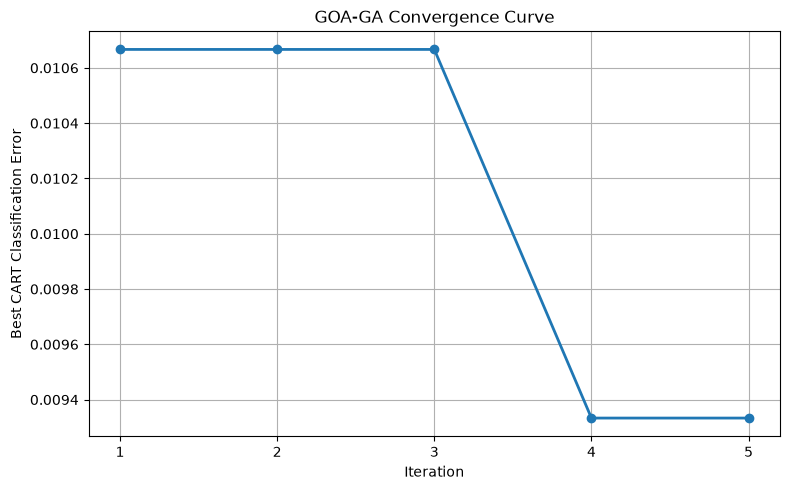

In [ ]:
import matplotlib.pyplot as plt

# Plot GOA-GA convergence

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Iteration"],
    history_df["Best_Error"],
    marker="o",
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel("Best CART Classification Error")
plt.title("GOA-GA Convergence Curve")

plt.xticks(history_df["Iteration"])
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Extract selected feature names

selected_feature_indices = np.where(best_solution == 1)[0]

selected_feature_names = [
    feature_names[i]
    for i in selected_feature_indices
]

print("Selected features:")
for i, feature in enumerate(selected_feature_names, start=1):
    print(f"{i}. {feature}")

print("\nTotal selected features:", len(selected_feature_names))
print("Original features:", len(feature_names))
print("Features removed:", len(feature_names) - len(selected_feature_names))

Selected features:
1. who CH
2. Dist_To_CH
3. ADV_S
4. ADV_R
5. JOIN_S
6. JOIN_R
7. SCH_S
8. SCH_R
9. Rank
10. DATA_S
11. Data_Sent_To_BS
12. dist_CH_To_BS
13. send_code
14. Expaned Energy

Total selected features: 14
Original features: 17
Features removed: 3


In [ ]:
# Final CART model using selected features

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Get selected feature indices
selected_indices = np.where(best_solution == 1)[0]

# Select features from complete training and testing datasets
X_train_selected = X_group_train_scaled[:, selected_indices]
X_test_selected = X_group_test_scaled[:, selected_indices]

# Create and train final CART model
final_cart = DecisionTreeClassifier(random_state=42)

final_cart.fit(X_train_selected, y_group_train)

# Predict test results
y_final_pred = final_cart.predict(X_test_selected)

# Calculate test accuracy
final_accuracy = accuracy_score(
    y_group_test,
    y_final_pred
)

print("Final CART model trained successfully!")
print("Training data shape:", X_train_selected.shape)
print("Testing data shape:", X_test_selected.shape)
print("Number of selected features:", len(selected_indices))
print("Final test accuracy:", final_accuracy)
print("Final test accuracy (%):", final_accuracy * 100)

Final CART model trained successfully!
Training data shape: (291855, 14)
Testing data shape: (73933, 14)
Number of selected features: 14
Final test accuracy: 0.9944950157575102
Final test accuracy (%): 99.44950157575101


In [ ]:
# Final CART classification report

from sklearn.metrics import classification_report

report = classification_report(
    y_group_test,
    y_final_pred,
    target_names=label_encoder.classes_,
    digits=4
)

print("FINAL CART CLASSIFICATION REPORT")
print("=" * 55)
print(report)

FINAL CART CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Blackhole     0.9847    0.9861    0.9854      2089
    Flooding     0.9583    0.9240    0.9408       671
    Grayhole     0.9742    0.9763    0.9752      2781
      Normal     0.9972    0.9975    0.9974     67029
        TDMA     0.9352    0.9310    0.9331      1363

    accuracy                         0.9945     73933
   macro avg     0.9699    0.9630    0.9664     73933
weighted avg     0.9945    0.9945    0.9945     73933



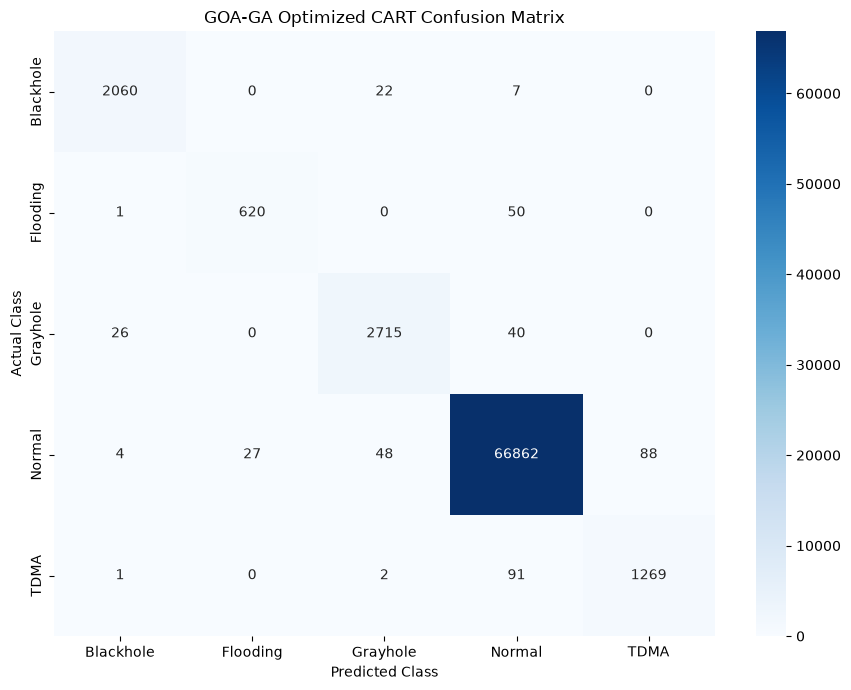

In [ ]:
# Generate confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_group_test,
    y_final_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("GOA-GA Optimized CART Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
# Compare baseline KNN and optimized CART

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

comparison_results = {
    "Model": [
        "Baseline KNN (17 features)",
        "GOA-GA Optimized CART (14 features)"
    ],

    "Accuracy": [
        accuracy_score(y_group_test, y_group_pred),
        accuracy_score(y_group_test, y_final_pred)
    ],

    "Macro Precision": [
        precision_score(
            y_group_test, y_group_pred, average="macro"
        ),
        precision_score(
            y_group_test, y_final_pred, average="macro"
        )
    ],

    "Macro Recall": [
        recall_score(
            y_group_test, y_group_pred, average="macro"
        ),
        recall_score(
            y_group_test, y_final_pred, average="macro"
        )
    ],

    "Macro F1": [
        f1_score(
            y_group_test, y_group_pred, average="macro"
        ),
        f1_score(
            y_group_test, y_final_pred, average="macro"
        )
    ],

    "Features": [17, 14]
}

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

NameError: name 'y_group_pred' is not defined

In [ ]:
# Recreate the baseline KNN model

from sklearn.neighbors import KNeighborsClassifier

group_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    n_jobs=-1
)

# Train using all 17 features
group_knn.fit(
    X_group_train_scaled,
    y_group_train
)

# Generate test predictions
y_group_pred = group_knn.predict(
    X_group_test_scaled
)

print("Baseline KNN predictions generated!")
print("Number of predictions:", len(y_group_pred))

Baseline KNN predictions generated!
Number of predictions: 73933


In [ ]:
# Compare baseline KNN and optimized CART

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

comparison_results = {
    "Model": [
        "Baseline KNN (17 features)",
        "GOA-GA Optimized CART (14 features)"
    ],

    "Accuracy": [
        accuracy_score(y_group_test, y_group_pred),
        accuracy_score(y_group_test, y_final_pred)
    ],

    "Macro Precision": [
        precision_score(y_group_test, y_group_pred, average="macro"),
        precision_score(y_group_test, y_final_pred, average="macro")
    ],

    "Macro Recall": [
        recall_score(y_group_test, y_group_pred, average="macro"),
        recall_score(y_group_test, y_final_pred, average="macro")
    ],

    "Macro F1": [
        f1_score(y_group_test, y_group_pred, average="macro"),
        f1_score(y_group_test, y_final_pred, average="macro")
    ],

    "Features": [17, 14]
}

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Features
0,Baseline KNN (17 features),0.9954,0.9747,0.969,0.9715,17
1,GOA-GA Optimized CART (14 features),0.9945,0.9699,0.963,0.9664,14


In [ ]:
# Controlled comparison: CART with all vs selected features

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Model A: CART with all 17 features
cart_all = DecisionTreeClassifier(random_state=42)

cart_all.fit(
    X_group_train_scaled,
    y_group_train
)

pred_all = cart_all.predict(
    X_group_test_scaled
)

# Model B: CART with 14 selected features
cart_selected = DecisionTreeClassifier(random_state=42)

cart_selected.fit(
    X_train_selected,
    y_group_train
)

pred_selected = cart_selected.predict(
    X_test_selected
)

# Compare both models
cart_comparison = pd.DataFrame({
    "Model": [
        "CART - All 17 Features",
        "CART - GOA-GA 14 Features"
    ],
    "Accuracy": [
        accuracy_score(y_group_test, pred_all),
        accuracy_score(y_group_test, pred_selected)
    ],
    "Macro Precision": [
        precision_score(y_group_test, pred_all, average="macro"),
        precision_score(y_group_test, pred_selected, average="macro")
    ],
    "Macro Recall": [
        recall_score(y_group_test, pred_all, average="macro"),
        recall_score(y_group_test, pred_selected, average="macro")
    ],
    "Macro F1": [
        f1_score(y_group_test, pred_all, average="macro"),
        f1_score(y_group_test, pred_selected, average="macro")
    ],
    "Features": [17, 14]
})

display(cart_comparison.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Features
0,CART - All 17 Features,0.9951,0.9713,0.9688,0.9700,17
1,CART - GOA-GA 14 Features,0.9945,0.9699,0.9630,0.9664,14


In [ ]:
# Save final experimental results

import joblib
import os

# Create results folder if it doesn't exist
os.makedirs("../results", exist_ok=True)

# Save comparison table
comparison_df.to_csv(
    "../results/knn_vs_optimized_cart.csv",
    index=False
)

cart_comparison.to_csv(
    "../results/cart_feature_comparison.csv",
    index=False
)

# Save final CART model and selected features
joblib.dump(
    {
        "model": final_cart,
        "selected_features": selected_feature_names,
        "selected_indices": selected_indices,
        "label_encoder": label_encoder
    },
    "../results/final_goa_ga_cart.pkl"
)

# Save optimization history
history_df.to_csv(
    "../results/goa_ga_optimization_history.csv",
    index=False
)

print("Experimental results saved successfully!")

Experimental results saved successfully!


In [ ]:
# Calculate feature importance from final CART model

import pandas as pd

feature_importance_df = pd.DataFrame({
    "Feature": selected_feature_names,
    "Importance": final_cart.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("CART FEATURE IMPORTANCE")
display(feature_importance_df.round(5))

CART FEATURE IMPORTANCE


,Feature,Importance
2,ADV_S,0.52843
13,Expaned Energy,0.22896
6,SCH_S,0.10686
11,dist_CH_To_BS,0.03835
10,Data_Sent_To_BS,0.03543
0,who CH,0.03121
5,JOIN_R,0.01456
3,ADV_R,0.00842
1,Dist_To_CH,0.00400
8,Rank,0.00278


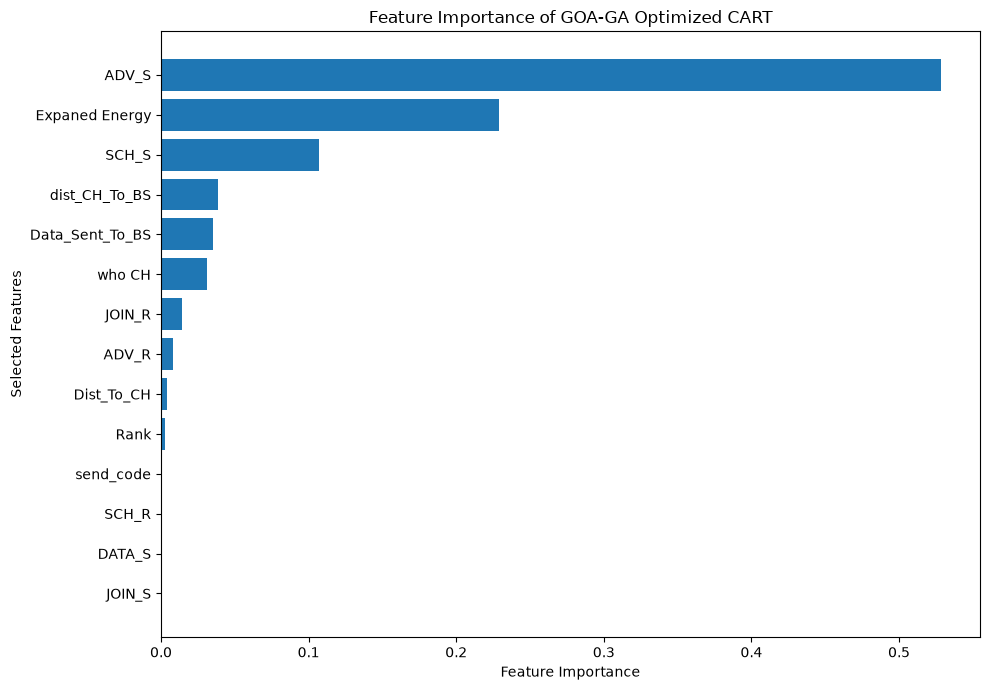

In [ ]:
# Plot CART feature importance

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Selected Features")
plt.title("Feature Importance of GOA-GA Optimized CART")

plt.gca().invert_yaxis()

plt.tight_layout()

# Save graph for internship report
plt.savefig(
    "../results/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("FINAL SELECTED FEATURES")
for feature in selected_feature_names:
    print("-", feature)

print("\nTotal selected features:", len(selected_feature_names))
print("Total original features:", len(feature_names))

FINAL SELECTED FEATURES
- who CH
- Dist_To_CH
- ADV_S
- ADV_R
- JOIN_S
- JOIN_R
- SCH_S
- SCH_R
- Rank
- DATA_S
- Data_Sent_To_BS
- dist_CH_To_BS
- send_code
- Expaned Energy

Total selected features: 14
Total original features: 17


In [ ]:
import numpy as np
import pandas as pd

# Keep the original starting population unchanged
initial_population = population.copy()

def run_one_experiment(seed):
    np.random.seed(seed)

    current_population = initial_population.copy()

    current_fitness = np.array([
        fitness_function(agent)
        for agent in current_population
    ])

    best_index = np.argmin(current_fitness)
    best_solution = current_population[best_index].copy()
    best_error = current_fitness[best_index]

    # Repeat GOA exploration and GA exploitation
    for iteration in range(1, max_iterations + 1):

        goa_population = goa_exploration(
            current_population, best_solution, iteration
        )

        goa_fitness = np.array([
            fitness_function(agent) for agent in goa_population
        ])

        ga_population, ga_fitness = ga_exploitation(goa_population)

        # Find the best solution from both populations
        combined_population = np.vstack(
            (goa_population, ga_population)
        )
        combined_fitness = np.concatenate(
            (goa_fitness, ga_fitness)
        )

        iteration_best = np.argmin(combined_fitness)

        if combined_fitness[iteration_best] < best_error:
            best_error = combined_fitness[iteration_best]
            best_solution = combined_population[iteration_best].copy()

        # Preserve the best solution through elitism
        current_population = ga_population.copy()
        current_fitness = ga_fitness.copy()

        worst_index = np.argmax(current_fitness)
        current_population[worst_index] = best_solution
        current_fitness[worst_index] = best_error

    selected = [
        feature_names[i]
        for i in np.where(best_solution == 1)[0]
    ]

    return selected, best_error


# Run the optimizer five times
experiment_results = []

for seed in [42, 100, 200, 300, 400]:

    selected, error = run_one_experiment(seed)

    experiment_results.append({
        "Seed": seed,
        "Selected_Feature_Count": len(selected),
        "Validation_Accuracy": (1 - error) * 100,
        "Selected_Features": selected
    })

results_df = pd.DataFrame(experiment_results)

display(
    results_df[
        ["Seed", "Selected_Feature_Count", "Validation_Accuracy"]
    ].round(3)
)

,Seed,Selected_Feature_Count,Validation_Accuracy
0,42,8,99.000
1,100,11,99.000
2,200,11,99.000
3,300,11,98.933
4,400,11,99.000


In [ ]:
from collections import Counter

# Count how often each feature was selected
feature_counts = Counter()

for selected_features in results_df["Selected_Features"]:
    feature_counts.update(selected_features)

# Create a frequency table
stability_df = pd.DataFrame({
    "Feature": feature_names,
    "Selection_Count": [
        feature_counts[feature] for feature in feature_names
    ]
})

stability_df["Selection_Percentage"] = (
    stability_df["Selection_Count"] / len(results_df)
) * 100

stability_df = stability_df.sort_values(
    by="Selection_Count",
    ascending=False
)

display(stability_df.round(2))

,Feature,Selection_Count,Selection_Percentage
16,Expaned Energy,5,100.0
13,Data_Sent_To_BS,5,100.0
4,ADV_S,5,100.0
5,ADV_R,5,100.0
7,JOIN_R,5,100.0
1,Is_CH,5,100.0
10,Rank,4,80.0
12,DATA_R,4,80.0
9,SCH_R,4,80.0
11,DATA_S,3,60.0


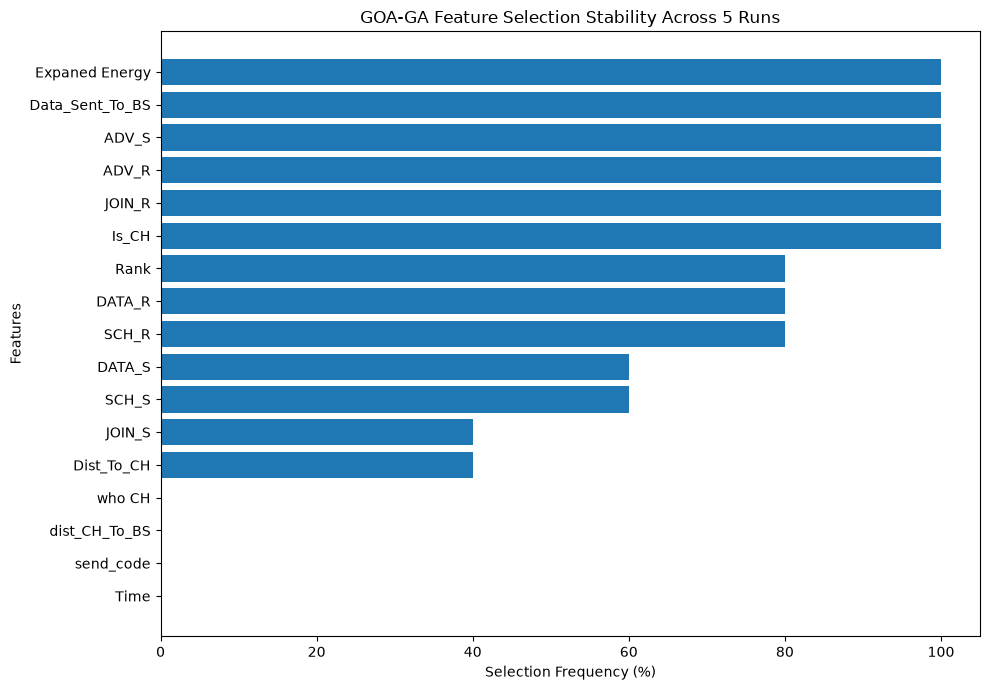

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.barh(
    stability_df["Feature"],
    stability_df["Selection_Percentage"]
)

plt.xlabel("Selection Frequency (%)")
plt.ylabel("Features")
plt.title("GOA-GA Feature Selection Stability Across 5 Runs")

plt.xlim(0, 105)
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "../results/feature_selection_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Identify the six consistently selected features
stable_features = stability_df.loc[
    stability_df["Selection_Count"] == 5,
    "Feature"
].tolist()

print("Stable features:")
for feature in stable_features:
    print("-", feature)

# Get their column indices
stable_indices = [
    feature_names.index(feature)
    for feature in stable_features
]

# Prepare training and testing data
X_train_stable = X_group_train_scaled[:, stable_indices]
X_test_stable = X_group_test_scaled[:, stable_indices]

# Train CART using only six stable features
stable_cart = DecisionTreeClassifier(random_state=42)

stable_cart.fit(X_train_stable, y_group_train)

# Predict test data
y_stable_pred = stable_cart.predict(X_test_stable)

# Evaluate performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("\nSIX-FEATURE CART RESULTS")
print("Accuracy:", accuracy_score(y_group_test, y_stable_pred))
print("Macro Precision:", precision_score(
    y_group_test, y_stable_pred, average="macro"
))
print("Macro Recall:", recall_score(
    y_group_test, y_stable_pred, average="macro"
))
print("Macro F1:", f1_score(
    y_group_test, y_stable_pred, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_group_test,
    y_stable_pred,
    target_names=label_encoder.classes_
))

Stable features:
- Expaned Energy
- Data_Sent_To_BS
- ADV_S
- ADV_R
- JOIN_R
- Is_CH

SIX-FEATURE CART RESULTS
Accuracy: 0.9835662018313879
Macro Precision: 0.8789371142041034
Macro Recall: 0.8673831603678961
Macro F1: 0.8728095954424979

Classification Report:
              precision    recall  f1-score   support

   Blackhole       0.83      0.86      0.84      2089
    Flooding       0.93      0.91      0.92       671
    Grayhole       0.98      0.97      0.97      2781
      Normal       1.00      1.00      1.00     67029
        TDMA       0.66      0.60      0.63      1363

    accuracy                           0.98     73933
   macro avg       0.88      0.87      0.87     73933
weighted avg       0.98      0.98      0.98     73933



,Model,Accuracy,Macro F1,Features
0,All 17 Features,99.5100,97.000,17
1,GOA-GA 14 Features,99.4495,96.640,14
2,Six Stable Features,98.3566,87.281,6


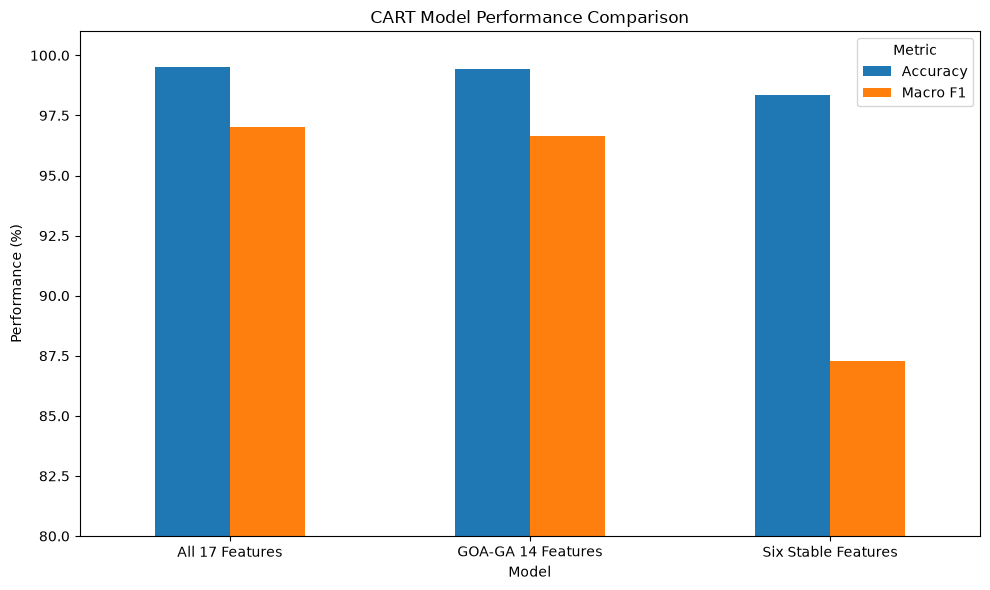

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

cart_models = pd.DataFrame({
    "Model": [
        "All 17 Features",
        "GOA-GA 14 Features",
        "Six Stable Features"
    ],
    "Accuracy": [99.51, 99.4495, 98.3566],
    "Macro F1": [97.00, 96.64, 87.281],
    "Features": [17, 14, 6]
})

display(cart_models)

# Plot accuracy and macro F1
ax = cart_models.set_index("Model")[
    ["Accuracy", "Macro F1"]
].plot(kind="bar", figsize=(10, 6))

ax.set_ylabel("Performance (%)")
ax.set_title("CART Model Performance Comparison")
ax.set_ylim(80, 101)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Metric")

plt.tight_layout()
plt.savefig(
    "../results/cart_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

cart_models.to_csv(
    "../results/cart_model_performance_comparison.csv",
    index=False
)

In [ ]:
import joblib

prepared_data = joblib.load("../dataset/processed/prepared_data.pkl")

X_group_train_scaled = prepared_data["X_group_train_scaled"]
X_group_test_scaled = prepared_data["X_group_test_scaled"]

y_group_train = prepared_data["y_group_train"]
y_group_test = prepared_data["y_group_test"]

label_encoder = prepared_data["label_encoder"]
group_scaler = prepared_data["group_scaler"]

feature_names = prepared_data["feature_names"]
train_groups = prepared_data["train_groups"]

print("Prepared data loaded successfully!")
print("Training data:", X_group_train_scaled.shape)
print("Testing data:", X_group_test_scaled.shape)
print("Number of features:", len(feature_names))
print("Features:", feature_names)

Prepared data loaded successfully!
Training data: (291855, 17)
Testing data: (73933, 17)
Number of features: 17
Features: ['Time', 'Is_CH', 'who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'DATA_R', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy']


In [ ]:
population_size = 10
number_of_features = len(feature_names)

max_iterations = 5

# GOA parameters
f = 0.5
l = 1.5
c_max = 1
c_min = 0.00004

# GA parameters
crossover_rate = 0.8
mutation_rate = 0.05

print("GOA-GA EXPERIMENT SETTINGS")
print("--------------------------")
print("Population size:", population_size)
print("Number of features:", number_of_features)
print("Maximum iterations:", max_iterations)

print("\nGOA parameters:")
print("f =", f)
print("l =", l)
print("c_max =", c_max)
print("c_min =", c_min)

print("\nGA settings:")
print("Crossover rate =", crossover_rate)
print("Mutation rate =", mutation_rate)

GOA-GA EXPERIMENT SETTINGS
--------------------------
Population size: 10
Number of features: 17
Maximum iterations: 5

GOA parameters:
f = 0.5
l = 1.5
c_max = 1
c_min = 4e-05

GA settings:
Crossover rate = 0.8
Mutation rate = 0.05


In [ ]:
import os

results_folder = "../results"

print("SAVED PROJECT RESULTS")
print("---------------------")

for file in sorted(os.listdir(results_folder)):
    print(file)

SAVED PROJECT RESULTS
---------------------
cart_feature_comparison.csv
cart_model_performance_comparison.csv
cart_model_performance_comparison.png
feature_importance.png
feature_selection_stability.png
final_goa_ga_cart.pkl
goa_ga_optimization_history.csv
knn_baseline.csv
knn_vs_optimized_cart.csv
per_class_recall_comparison.png


In [ ]:
import joblib

saved_model = joblib.load("../results/final_goa_ga_cart.pkl")

print("SAVED MODEL VERIFICATION")
print("------------------------")

print("Available items:", saved_model.keys())

print("\nSelected features:")
print(saved_model["selected_features"])

print("\nNumber of selected features:",
      len(saved_model["selected_features"]))

print("\nModel type:", type(saved_model["model"]).__name__)

SAVED MODEL VERIFICATION
------------------------
Available items: dict_keys(['model', 'selected_features', 'selected_indices', 'label_encoder'])

Selected features:
['who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy']

Number of selected features: 14

Model type: DecisionTreeClassifier


In [ ]:
def improved_fitness_function(solution):
    selected_features = np.where(solution == 1)[0]

    if len(selected_features) == 0:
        return 1.0

    X_train_selected = X_fitness_train[:, selected_features]
    X_val_selected = X_fitness_val[:, selected_features]

    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train_selected, y_fitness_train)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_fitness_val, predictions)
    classification_error = 1 - accuracy

    feature_penalty = len(selected_features) / number_of_features

    fitness = (
        0.9 * classification_error
        + 0.1 * feature_penalty
    )

    return fitness

print("Improved fitness function created successfully!")

Improved fitness function created successfully!


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Recreate group-wise training and validation split
validation_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

subtrain_idx, val_idx = next(
    validation_split.split(
        X_group_train_scaled,
        y_group_train,
        groups=train_groups
    )
)

X_subtrain = X_group_train_scaled[subtrain_idx]
X_val = X_group_train_scaled[val_idx]

y_subtrain = y_group_train[subtrain_idx]
y_val = y_group_train[val_idx]

# Recreate the same stratified samples
train_indices, _ = train_test_split(
    np.arange(len(y_subtrain)),
    train_size=5000,
    random_state=42,
    stratify=y_subtrain
)

val_indices, _ = train_test_split(
    np.arange(len(y_val)),
    train_size=1500,
    random_state=42,
    stratify=y_val
)

X_fitness_train = X_subtrain[train_indices]
X_fitness_val = X_val[val_indices]

y_fitness_train = y_subtrain[train_indices]
y_fitness_val = y_val[val_indices]

print("Fitness evaluation data restored!")
print("Fitness training:", X_fitness_train.shape)
print("Fitness validation:", X_fitness_val.shape)
print("Training-validation group overlap:",
      len(set(train_groups[subtrain_idx]) &
          set(train_groups[val_idx])))

Fitness evaluation data restored!
Fitness training: (5000, 17)
Fitness validation: (1500, 17)
Training-validation group overlap: 0


In [ ]:
# Recreate the original baseline fitness function
def original_fitness_function(solution):
    selected_features = np.where(solution == 1)[0]

    if len(selected_features) == 0:
        return 1.0

    X_train_selected = X_fitness_train[:, selected_features]
    X_val_selected = X_fitness_val[:, selected_features]

    model = DecisionTreeClassifier(random_state=42)
    model.fit(X_train_selected, y_fitness_train)

    predictions = model.predict(X_val_selected)
    accuracy = accuracy_score(y_fitness_val, predictions)

    return 1 - accuracy


# Load the original 14-feature solution
baseline_solution = np.zeros(number_of_features, dtype=int)

baseline_solution[saved_model["selected_indices"]] = 1

# Evaluate both fitness functions
original_score = original_fitness_function(baseline_solution)
improved_score = improved_fitness_function(baseline_solution)

print("FITNESS FUNCTION COMPARISON")
print("----------------------------")
print("Selected features:", np.sum(baseline_solution))
print("Original fitness:", round(original_score, 5))
print("Improved fitness:", round(improved_score, 5))

FITNESS FUNCTION COMPARISON
----------------------------
Selected features: 14
Original fitness: 0.00933
Improved fitness: 0.09075


In [ ]:
np.random.seed(42)

improved_population = np.random.randint(
    0, 2,
    size=(population_size, number_of_features)
)

# Ensure every solution selects at least one feature
for i in range(population_size):
    if np.sum(improved_population[i]) == 0:
        random_feature = np.random.randint(number_of_features)
        improved_population[i, random_feature] = 1

# Evaluate using improved fitness
improved_population_fitness = np.array([
    improved_fitness_function(agent)
    for agent in improved_population
])

print("IMPROVED POPULATION CREATED")
print("----------------------------")
print("Population shape:", improved_population.shape)
print("Feature counts:", np.sum(improved_population, axis=1))
print("Fitness scores:", np.round(improved_population_fitness, 5))

best_index = np.argmin(improved_population_fitness)

print("\nBest initial fitness:", round(improved_population_fitness[best_index], 5))
print("Features selected:", np.sum(improved_population[best_index]))

IMPROVED POPULATION CREATED
----------------------------
Population shape: (10, 17)
Feature counts: [ 5 13  9  6 11 13 13  7  5  8]
Fitness scores: [0.05521 0.09627 0.09554 0.07849 0.08691 0.08667 0.08727 0.11138 0.05161
 0.06866]

Best initial fitness: 0.05161
Features selected: 5


In [ ]:
def social_function(distance):
    return f * np.exp(-distance / l) - np.exp(-distance)


def calculate_c(iteration):
    return c_max - (
        iteration * (c_max - c_min) / max_iterations
    )


def stochastic_binary_conversion(position):
    probabilities = 1 / (1 + np.exp(-position))

    random_values = np.random.random(len(position))

    binary_solution = (
        random_values < probabilities
    ).astype(int)

    if np.sum(binary_solution) == 0:
        binary_solution[np.argmax(probabilities)] = 1

    return binary_solution


print("GOA exploration helper functions restored!")

GOA exploration helper functions restored!


In [ ]:
def goa_exploration_improved(current_population, best_solution, iteration):

    pop_size = len(current_population)

    # Convert binary solutions into continuous positions
    positions = np.where(current_population == 1, 1.0, -1.0)

    best_position = np.where(best_solution == 1, 1.0, -1.0)

    # Calculate distances
    distance_matrix = np.zeros((pop_size, pop_size))

    for i in range(pop_size):
        for j in range(pop_size):
            distance_matrix[i, j] = np.linalg.norm(
                positions[i] - positions[j]
            )

    # Calculate social forces
    social_force = np.zeros_like(positions)

    for i in range(pop_size):
        for j in range(pop_size):

            if i != j:
                distance = distance_matrix[i, j]

                interaction = social_function(distance)

                direction = (
                    positions[j] - positions[i]
                ) / (distance + 1e-10)

                social_force[i] += interaction * direction

    # Update positions
    c = calculate_c(iteration)

    updated_positions = (
        c * social_force + best_position
    )

    updated_positions = np.clip(
        updated_positions, -1, 1
    )

    # Convert positions into binary solutions
    updated_population = np.array([
        stochastic_binary_conversion(updated_positions[i])
        for i in range(pop_size)
    ])

    return updated_population


print("Improved GOA exploration operator created successfully!")

Improved GOA exploration operator created successfully!


In [ ]:
def tournament_selection_improved(population, fitness_values):
    selected_parents = []

    for _ in range(len(population)):

        candidates = np.random.choice(
            len(population),
            size=2,
            replace=False
        )

        winner = candidates[
            np.argmin(fitness_values[candidates])
        ]

        selected_parents.append(population[winner])

    return np.array(selected_parents)


def crossover_improved(parent1, parent2):
    child1 = parent1.copy()
    child2 = parent2.copy()

    if np.random.random() < crossover_rate:

        crossover_point = np.random.randint(
            1, number_of_features
        )

        child1 = np.concatenate((
            parent1[:crossover_point],
            parent2[crossover_point:]
        ))

        child2 = np.concatenate((
            parent2[:crossover_point],
            parent1[crossover_point:]
        ))

    return child1, child2


def mutation_improved(child):
    mutated_child = child.copy()

    for i in range(len(mutated_child)):

        if np.random.random() < mutation_rate:
            mutated_child[i] = 1 - mutated_child[i]

    if np.sum(mutated_child) == 0:
        random_feature = np.random.randint(number_of_features)
        mutated_child[random_feature] = 1

    return mutated_child


print("GA helper functions created successfully!")

GA helper functions created successfully!


In [ ]:
# Initialize improved optimization
current_population = improved_population.copy()
current_fitness = improved_population_fitness.copy()

best_index = np.argmin(current_fitness)

best_solution = current_population[best_index].copy()
best_fitness = current_fitness[best_index]

improved_history = []

# Run GOA-GA optimization
for iteration in range(1, max_iterations + 1):

    # GOA exploration
    goa_population = goa_exploration_improved(
        current_population,
        best_solution,
        iteration
    )

    goa_fitness = np.array([
        improved_fitness_function(agent)
        for agent in goa_population
    ])

    # GA exploitation
    parents = tournament_selection_improved(
        goa_population,
        goa_fitness
    )

    children = []

    for i in range(0, population_size, 2):
        child1, child2 = crossover_improved(
            parents[i],
            parents[i + 1]
        )

        children.extend([child1, child2])

    mutated_children = np.array([
        mutation_improved(child)
        for child in children
    ])

    ga_fitness = np.array([
        improved_fitness_function(agent)
        for agent in mutated_children
    ])

    # Combine GOA and GA candidates
    combined_population = np.vstack((
        goa_population,
        mutated_children
    ))

    combined_fitness = np.concatenate((
        goa_fitness,
        ga_fitness
    ))

    # Find the best candidate
    iteration_best_index = np.argmin(combined_fitness)

    iteration_best_solution = combined_population[
        iteration_best_index
    ].copy()

    iteration_best_fitness = combined_fitness[
        iteration_best_index
    ]

    # Update best solution
    if iteration_best_fitness < best_fitness:
        best_fitness = iteration_best_fitness
        best_solution = iteration_best_solution.copy()

    # Elitism: preserve the best solution
    current_population = mutated_children.copy()
    current_fitness = ga_fitness.copy()

    worst_index = np.argmax(current_fitness)

    current_population[worst_index] = best_solution
    current_fitness[worst_index] = best_fitness

    # Save iteration results
    improved_history.append({
        "Iteration": iteration,
        "Best_Fitness": best_fitness,
        "Selected_Features": int(np.sum(best_solution))
    })

    print(
        f"Iteration {iteration}: "
        f"Best Fitness = {best_fitness:.5f}, "
        f"Features = {np.sum(best_solution)}"
    )

print("\nImproved GOA-GA optimization completed!")

Iteration 1: Best Fitness = 0.04489, Features = 6
Iteration 2: Best Fitness = 0.04489, Features = 6
Iteration 3: Best Fitness = 0.03445, Features = 3
Iteration 4: Best Fitness = 0.03445, Features = 3
Iteration 5: Best Fitness = 0.03445, Features = 3

Improved GOA-GA optimization completed!


In [ ]:
improved_selected_indices = np.where(best_solution == 1)[0]

improved_selected_features = [
    feature_names[i]
    for i in improved_selected_indices
]

# Evaluate validation performance
X_val_selected = X_fitness_val[:, improved_selected_indices]

improved_validation_model = DecisionTreeClassifier(random_state=42)

improved_validation_model.fit(
    X_fitness_train[:, improved_selected_indices],
    y_fitness_train
)

improved_val_predictions = improved_validation_model.predict(
    X_val_selected
)

improved_val_accuracy = accuracy_score(
    y_fitness_val,
    improved_val_predictions
)

print("IMPROVED GOA-GA RESULTS")
print("----------------------")
print("Selected features:", improved_selected_features)
print("Number of features:", len(improved_selected_features))
print("Validation accuracy:", round(improved_val_accuracy * 100, 4), "%")
print("Best fitness:", round(best_fitness, 5))

IMPROVED GOA-GA RESULTS
----------------------
Selected features: ['ADV_S', 'SCH_S', 'Expaned Energy']
Number of features: 3
Validation accuracy: 98.1333 %
Best fitness: 0.03445


In [ ]:
# Select the three features from training and test datasets

X_improved_train = X_group_train_scaled[:, improved_selected_indices]
X_improved_test = X_group_test_scaled[:, improved_selected_indices]

# Train the final Decision Tree model
improved_final_cart = DecisionTreeClassifier(random_state=42)

improved_final_cart.fit(
    X_improved_train,
    y_group_train
)

# Predict test results
y_improved_pred = improved_final_cart.predict(
    X_improved_test
)

# Calculate test accuracy
improved_test_accuracy = accuracy_score(
    y_group_test,
    y_improved_pred
)

print("THREE-FEATURE MODEL TEST RESULTS")
print("--------------------------------")
print("Selected features:", improved_selected_features)
print("Training shape:", X_improved_train.shape)
print("Testing shape:", X_improved_test.shape)

print(
    "Test accuracy:",
    round(improved_test_accuracy * 100, 4),
    "%"
)

THREE-FEATURE MODEL TEST RESULTS
--------------------------------
Selected features: ['ADV_S', 'SCH_S', 'Expaned Energy']
Training shape: (291855, 3)
Testing shape: (73933, 3)
Test accuracy: 98.2376 %


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("THREE-FEATURE MODEL: CLASSIFICATION REPORT")
print("------------------------------------------")

print(
    classification_report(
        y_group_test,
        y_improved_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)

print("\nCONFUSION MATRIX")
print("----------------")

cm_improved = confusion_matrix(
    y_group_test,
    y_improved_pred
)

print(cm_improved)

THREE-FEATURE MODEL: CLASSIFICATION REPORT
------------------------------------------
              precision    recall  f1-score   support

   Blackhole     0.8887    0.9215    0.9048      2089
    Flooding     0.9397    0.9285    0.9340       671
    Grayhole     0.8508    0.8425    0.8466      2781
      Normal     0.9920    0.9929    0.9925     67029
        TDMA     0.9396    0.8679    0.9024      1363

    accuracy                         0.9824     73933
   macro avg     0.9222    0.9107    0.9161     73933
weighted avg     0.9824    0.9824    0.9823     73933


CONFUSION MATRIX
----------------
[[ 1925     0    80    77     7]
 [    0   623     1    47     0]
 [  141     0  2343   280    17]
 [   88    40   293 66556    52]
 [   12     0    37   131  1183]]


In [ ]:
def balanced_fitness_function(solution):

    selected_features = np.where(solution == 1)[0]

    if len(selected_features) == 0:
        return 1.0

    X_train_selected = X_fitness_train[:, selected_features]
    X_val_selected = X_fitness_val[:, selected_features]

    model = DecisionTreeClassifier(random_state=42)

    model.fit(X_train_selected, y_fitness_train)

    predictions = model.predict(X_val_selected)

    accuracy = accuracy_score(y_fitness_val, predictions)

    classification_error = 1 - accuracy

    feature_penalty = len(selected_features) / number_of_features

    fitness = (
        0.95 * classification_error
        + 0.05 * feature_penalty
    )

    return fitness


print("Balanced fitness function created!")
print("Classification weight: 0.95")
print("Feature reduction weight: 0.05")

Balanced fitness function created!
Classification weight: 0.95
Feature reduction weight: 0.05


In [ ]:
np.random.seed(100)

balanced_population = np.random.randint(
    0, 2,
    size=(population_size, number_of_features)
)

# Ensure every solution has at least one feature
for i in range(population_size):
    if np.sum(balanced_population[i]) == 0:
        random_feature = np.random.randint(number_of_features)
        balanced_population[i, random_feature] = 1

# Evaluate population using balanced fitness
balanced_fitness_values = np.array([
    balanced_fitness_function(agent)
    for agent in balanced_population
])

print("BALANCED POPULATION")
print("-------------------")
print("Population shape:", balanced_population.shape)
print("Feature counts:", np.sum(balanced_population, axis=1))
print("Fitness scores:", np.round(balanced_fitness_values, 5))

best_index = np.argmin(balanced_fitness_values)

print("\nBest initial fitness:", round(balanced_fitness_values[best_index], 5))
print("Selected features:", np.sum(balanced_population[best_index]))

BALANCED POPULATION
-------------------
Population shape: (10, 17)
Feature counts: [ 6  7 14  9  7  8  8  5  9  9]
Fitness scores: [0.04868 0.03515 0.05828 0.03977 0.04275 0.06406 0.0495  0.06537 0.0461
 0.0461 ]

Best initial fitness: 0.03515
Selected features: 7


In [ ]:
# Initialize balanced optimization
balanced_current_population = balanced_population.copy()
balanced_current_fitness = balanced_fitness_values.copy()

best_index = np.argmin(balanced_current_fitness)

balanced_best_solution = (
    balanced_current_population[best_index].copy()
)

balanced_best_fitness = balanced_current_fitness[best_index]

balanced_history = []

# Run optimization
for iteration in range(1, max_iterations + 1):

    # GOA exploration
    goa_population = goa_exploration_improved(
        balanced_current_population,
        balanced_best_solution,
        iteration
    )

    goa_fitness = np.array([
        balanced_fitness_function(agent)
        for agent in goa_population
    ])

    # GA exploitation
    parents = tournament_selection_improved(
        goa_population,
        goa_fitness
    )

    children = []

    for i in range(0, population_size, 2):

        child1, child2 = crossover_improved(
            parents[i],
            parents[i + 1]
        )

        children.extend([child1, child2])

    mutated_children = np.array([
        mutation_improved(child)
        for child in children
    ])

    ga_fitness = np.array([
        balanced_fitness_function(agent)
        for agent in mutated_children
    ])

    # Combine GOA and GA solutions
    combined_population = np.vstack((
        goa_population,
        mutated_children
    ))

    combined_fitness = np.concatenate((
        goa_fitness,
        ga_fitness
    ))

    iteration_best_index = np.argmin(combined_fitness)

    iteration_best_solution = (
        combined_population[iteration_best_index].copy()
    )

    iteration_best_fitness = (
        combined_fitness[iteration_best_index]
    )

    # Update global best
    if iteration_best_fitness < balanced_best_fitness:

        balanced_best_fitness = iteration_best_fitness

        balanced_best_solution = (
            iteration_best_solution.copy()
        )

    # Elitism
    balanced_current_population = mutated_children.copy()
    balanced_current_fitness = ga_fitness.copy()

    worst_index = np.argmax(balanced_current_fitness)

    balanced_current_population[worst_index] = (
        balanced_best_solution
    )

    balanced_current_fitness[worst_index] = (
        balanced_best_fitness
    )

    balanced_history.append({
        "Iteration": iteration,
        "Best_Fitness": balanced_best_fitness,
        "Selected_Features": int(
            np.sum(balanced_best_solution)
        )
    })

    print(
        f"Iteration {iteration}: "
        f"Best Fitness = {balanced_best_fitness:.5f}, "
        f"Features = {np.sum(balanced_best_solution)}"
    )

print("\nBalanced GOA-GA optimization completed!")

Iteration 1: Best Fitness = 0.02968, Features = 6
Iteration 2: Best Fitness = 0.02968, Features = 6
Iteration 3: Best Fitness = 0.02968, Features = 6
Iteration 4: Best Fitness = 0.02968, Features = 6
Iteration 5: Best Fitness = 0.02968, Features = 6

Balanced GOA-GA optimization completed!


In [ ]:
balanced_selected_indices = np.where(
    balanced_best_solution == 1
)[0]

balanced_selected_features = [
    feature_names[i]
    for i in balanced_selected_indices
]

# Train validation model
balanced_validation_model = DecisionTreeClassifier(
    random_state=42
)

balanced_validation_model.fit(
    X_fitness_train[:, balanced_selected_indices],
    y_fitness_train
)

balanced_val_predictions = balanced_validation_model.predict(
    X_fitness_val[:, balanced_selected_indices]
)

balanced_val_accuracy = accuracy_score(
    y_fitness_val,
    balanced_val_predictions
)

print("BALANCED GOA-GA RESULTS")
print("-----------------------")
print("Selected features:", balanced_selected_features)
print("Number of features:", len(balanced_selected_features))
print("Validation accuracy:",
      round(balanced_val_accuracy * 100, 4), "%")
print("Best fitness:", round(balanced_best_fitness, 5))

BALANCED GOA-GA RESULTS
-----------------------
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Number of features: 6
Validation accuracy: 98.7333 %
Best fitness: 0.02968


In [ ]:
# Prepare selected training and test data

X_balanced_train = X_group_train_scaled[:, balanced_selected_indices]
X_balanced_test = X_group_test_scaled[:, balanced_selected_indices]

# Train final CART model

balanced_final_cart = DecisionTreeClassifier(random_state=42)

balanced_final_cart.fit(
    X_balanced_train,
    y_group_train
)

# Predict test data

y_balanced_pred = balanced_final_cart.predict(
    X_balanced_test
)

# Calculate test accuracy

balanced_test_accuracy = accuracy_score(
    y_group_test,
    y_balanced_pred
)

print("SIX-FEATURE MODEL TEST RESULTS")
print("--------------------------------")
print("Selected features:", balanced_selected_features)
print("Training shape:", X_balanced_train.shape)
print("Testing shape:", X_balanced_test.shape)

print(
    "Test accuracy:",
    round(balanced_test_accuracy * 100, 4),
    "%"
)

SIX-FEATURE MODEL TEST RESULTS
--------------------------------
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Training shape: (291855, 6)
Testing shape: (73933, 6)
Test accuracy: 99.4373 %


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("SIX-FEATURE MODEL: CLASSIFICATION REPORT")
print("-----------------------------------------")

print(
    classification_report(
        y_group_test,
        y_balanced_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)

print("\nCONFUSION MATRIX")
print("----------------")

balanced_cm = confusion_matrix(
    y_group_test,
    y_balanced_pred
)

print(balanced_cm)

SIX-FEATURE MODEL: CLASSIFICATION REPORT
-----------------------------------------
              precision    recall  f1-score   support

   Blackhole     0.9795    0.9832    0.9814      2089
    Flooding     0.9422    0.9240    0.9330       671
    Grayhole     0.9748    0.9748    0.9748      2781
      Normal     0.9973    0.9975    0.9974     67029
        TDMA     0.9373    0.9318    0.9345      1363

    accuracy                         0.9944     73933
   macro avg     0.9662    0.9623    0.9642     73933
weighted avg     0.9944    0.9944    0.9944     73933


CONFUSION MATRIX
----------------
[[ 2054     0    27     8     0]
 [    0   620     0    51     0]
 [   38     0  2711    31     1]
 [    4    38    41 66862    84]
 [    1     0     2    90  1270]]


In [ ]:
import joblib
import os

balanced_model_data = {
    "model": balanced_final_cart,
    "selected_features": balanced_selected_features,
    "selected_indices": balanced_selected_indices,
    "label_encoder": label_encoder,
    "fitness_weight_accuracy": 0.95,
    "fitness_weight_features": 0.05,
    "test_accuracy": balanced_test_accuracy
}

joblib.dump(
    balanced_model_data,
    "../results/final_balanced_goa_ga_cart.pkl"
)

print("Six-feature model saved successfully!")
print("File: final_balanced_goa_ga_cart.pkl")
print("Selected features:", len(balanced_selected_features))
print("Test accuracy:", round(balanced_test_accuracy * 100, 4), "%")

Six-feature model saved successfully!
File: final_balanced_goa_ga_cart.pkl
Selected features: 6
Test accuracy: 99.4373 %


In [ ]:
import joblib

verified_model = joblib.load(
    "../results/final_balanced_goa_ga_cart.pkl"
)

print("MODEL VERIFICATION")
print("------------------")

print("Model type:", type(verified_model["model"]).__name__)

print("Selected features:",
      verified_model["selected_features"])

print("Number of features:",
      len(verified_model["selected_features"]))

print("Saved test accuracy:",
      round(verified_model["test_accuracy"] * 100, 4), "%")

print("\nModel loaded successfully!")

MODEL VERIFICATION
------------------
Model type: DecisionTreeClassifier
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Number of features: 6
Saved test accuracy: 99.4373 %

Model loaded successfully!


In [ ]:
def run_balanced_experiment(seed):

    np.random.seed(seed)

    population = np.random.randint(
        0, 2,
        size=(population_size, number_of_features)
    )

    for i in range(population_size):
        if np.sum(population[i]) == 0:
            random_feature = np.random.randint(number_of_features)
            population[i, random_feature] = 1

    fitness_values = np.array([
        balanced_fitness_function(agent)
        for agent in population
    ])

    best_index = np.argmin(fitness_values)
    best_solution = population[best_index].copy()
    best_fitness = fitness_values[best_index]

    for iteration in range(1, max_iterations + 1):

        goa_population = goa_exploration_improved(
            population,
            best_solution,
            iteration
        )

        goa_fitness = np.array([
            balanced_fitness_function(agent)
            for agent in goa_population
        ])

        parents = tournament_selection_improved(
            goa_population,
            goa_fitness
        )

        children = []

        for i in range(0, population_size, 2):
            child1, child2 = crossover_improved(
                parents[i], parents[i + 1]
            )
            children.extend([child1, child2])

        children = np.array([
            mutation_improved(child)
            for child in children
        ])

        child_fitness = np.array([
            balanced_fitness_function(agent)
            for agent in children
        ])

        combined_population = np.vstack((
            goa_population, children
        ))

        combined_fitness = np.concatenate((
            goa_fitness, child_fitness
        ))

        iteration_best = np.argmin(combined_fitness)

        if combined_fitness[iteration_best] < best_fitness:
            best_fitness = combined_fitness[iteration_best]
            best_solution = combined_population[iteration_best].copy()

        population = children.copy()
        fitness_values = child_fitness.copy()

        worst_index = np.argmax(fitness_values)

        population[worst_index] = best_solution
        fitness_values[worst_index] = best_fitness

    return best_solution, best_fitness


print("Balanced experiment function created successfully!")

Balanced experiment function created successfully!


In [ ]:
seeds = [42, 100, 200, 300, 400]

stability_results = []

for seed in seeds:

    solution, fitness = run_balanced_experiment(seed)

    selected_indices = np.where(solution == 1)[0]

    selected_features = [
        feature_names[i] for i in selected_indices
    ]

    # Calculate validation accuracy
    model = DecisionTreeClassifier(random_state=42)

    model.fit(
        X_fitness_train[:, selected_indices],
        y_fitness_train
    )

    predictions = model.predict(
        X_fitness_val[:, selected_indices]
    )

    validation_accuracy = accuracy_score(
        y_fitness_val,
        predictions
    )

    stability_results.append({
        "Seed": seed,
        "Features_Selected": len(selected_features),
        "Validation_Accuracy": validation_accuracy * 100,
        "Selected_Features": selected_features
    })

    print(
        f"Seed {seed}: "
        f"{len(selected_features)} features, "
        f"Validation Accuracy = {validation_accuracy * 100:.4f}%"
    )

print("\nFive-seed stability experiment completed!")

Seed 42: 5 features, Validation Accuracy = 98.9333%
Seed 100: 6 features, Validation Accuracy = 98.7333%
Seed 200: 6 features, Validation Accuracy = 98.8667%
Seed 300: 5 features, Validation Accuracy = 98.3333%
Seed 400: 7 features, Validation Accuracy = 98.8667%

Five-seed stability experiment completed!


In [ ]:
from collections import Counter

feature_counter = Counter()

for result in stability_results:
    feature_counter.update(result["Selected_Features"])

stability_df = pd.DataFrame({
    "Feature": feature_names,
    "Selection_Count": [
        feature_counter[feature] for feature in feature_names
    ]
})

stability_df["Selection_Percentage"] = (
    stability_df["Selection_Count"] / len(seeds) * 100
)

stability_df = stability_df.sort_values(
    by="Selection_Count",
    ascending=False
).reset_index(drop=True)

print("FEATURE SELECTION STABILITY")
print("---------------------------")

display(stability_df.round(2))

print("\nAverage selected features:",
      np.mean([r["Features_Selected"] for r in stability_results]))

print("Average validation accuracy:",
      round(np.mean([
          r["Validation_Accuracy"] for r in stability_results
      ]), 4), "%")

FEATURE SELECTION STABILITY
---------------------------


,Feature,Selection_Count,Selection_Percentage
0,SCH_S,5,100.0
1,Data_Sent_To_BS,5,100.0
2,Expaned Energy,5,100.0
3,ADV_S,4,80.0
4,JOIN_R,2,40.0
5,DATA_S,2,40.0
6,who CH,2,40.0
7,Dist_To_CH,1,20.0
8,ADV_R,1,20.0
9,SCH_R,1,20.0



Average selected features: 5.8
Average validation accuracy: 98.7467 %


In [ ]:
# Save stability table
stability_df.to_csv(
    "../results/balanced_feature_stability.csv",
    index=False
)

# Save individual experiment results
stability_results_df = pd.DataFrame(stability_results)

stability_results_df.to_csv(
    "../results/balanced_five_seed_results.csv",
    index=False
)

# Save optimization history
pd.DataFrame(balanced_history).to_csv(
    "../results/balanced_optimization_history.csv",
    index=False
)

print("STABILITY RESULTS SAVED")
print("-----------------------")
print("1. balanced_feature_stability.csv")
print("2. balanced_five_seed_results.csv")
print("3. balanced_optimization_history.csv")

STABILITY RESULTS SAVED
-----------------------
1. balanced_feature_stability.csv
2. balanced_five_seed_results.csv
3. balanced_optimization_history.csv


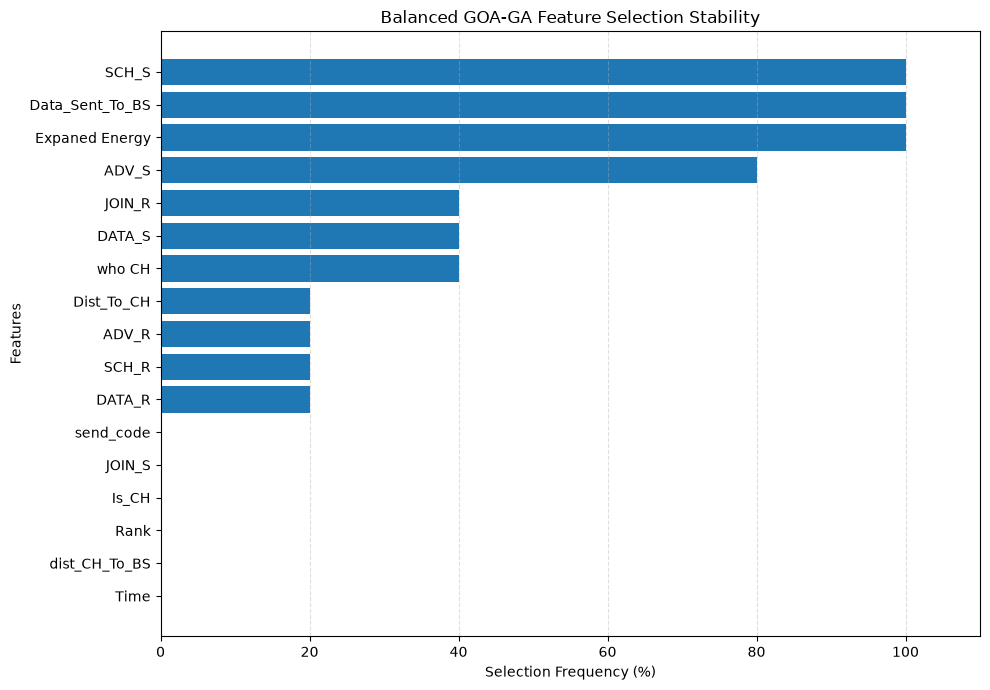

Feature stability graph saved successfully!


In [ ]:
import matplotlib.pyplot as plt

plot_df = stability_df.sort_values(
    by="Selection_Percentage",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["Selection_Percentage"]
)

plt.xlabel("Selection Frequency (%)")
plt.ylabel("Features")
plt.title("Balanced GOA-GA Feature Selection Stability")

plt.xlim(0, 110)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "../results/balanced_feature_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Feature stability graph saved successfully!")

In [ ]:
import joblib

# Load the previously saved prepared dataset
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

X_group_train_scaled = prepared_data["X_group_train_scaled"]
y_group_train = prepared_data["y_group_train"]
train_groups = prepared_data["train_groups"]
feature_names = prepared_data["feature_names"]

# Use the already-scaled training data
X_group_train = X_group_train_scaled

print("DATA RESTORED SUCCESSFULLY")
print("--------------------------")
print("Training data:", X_group_train.shape)
print("Training labels:", y_group_train.shape)
print("Node IDs:", train_groups.shape)
print("Features:", len(feature_names))

DATA RESTORED SUCCESSFULLY
--------------------------
Training data: (291855, 17)
Training labels: (291855,)
Node IDs: (291855,)
Features: 17


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# Select the six balanced GOA-GA features
balanced_selected_features = [
    "who CH",
    "ADV_S",
    "JOIN_R",
    "SCH_S",
    "Data_Sent_To_BS",
    "Expaned Energy"
]

selected_indices = [
    feature_names.index(feature)
    for feature in balanced_selected_features
]

# Create a new split using a different random seed
new_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=100
)

new_train_idx, new_val_idx = next(
    new_split.split(
        X_group_train,
        y_group_train,
        groups=train_groups
    )
)

# Select the six features
X_new_train = X_group_train[new_train_idx][:, selected_indices]
X_new_val = X_group_train[new_val_idx][:, selected_indices]

y_new_train = y_group_train[new_train_idx]
y_new_val = y_group_train[new_val_idx]

# Check node separation
train_node_ids = set(train_groups[new_train_idx])
val_node_ids = set(train_groups[new_val_idx])

print("NEW GENERALIZATION SPLIT")
print("------------------------")
print("Training shape:", X_new_train.shape)
print("Validation shape:", X_new_val.shape)
print("Training nodes:", len(train_node_ids))
print("Validation nodes:", len(val_node_ids))
print("Overlapping node IDs:", len(train_node_ids.intersection(val_node_ids)))

NEW GENERALIZATION SPLIT
------------------------
Training shape: (230568, 6)
Validation shape: (61287, 6)
Training nodes: 7116
Validation nodes: 1780
Overlapping node IDs: 0


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Create and train a fresh CART model
generalization_cart = DecisionTreeClassifier(random_state=42)

generalization_cart.fit(
    X_new_train,
    y_new_train
)

# Predict validation results
y_new_pred = generalization_cart.predict(X_new_val)

# Calculate evaluation metrics
new_accuracy = accuracy_score(y_new_val, y_new_pred)
new_precision = precision_score(
    y_new_val, y_new_pred, average="macro"
)
new_recall = recall_score(
    y_new_val, y_new_pred, average="macro"
)
new_f1 = f1_score(
    y_new_val, y_new_pred, average="macro"
)

print("GENERALIZATION TEST RESULTS")
print("---------------------------")
print("Accuracy:", round(new_accuracy * 100, 4), "%")
print("Macro Precision:", round(new_precision * 100, 4), "%")
print("Macro Recall:", round(new_recall * 100, 4), "%")
print("Macro F1:", round(new_f1 * 100, 4), "%")

print("\nCLASSIFICATION REPORT")
print("---------------------")
print(classification_report(
    y_new_val,
    y_new_pred,
    target_names=label_encoder.classes_
))

print("\nCONFUSION MATRIX")
print("----------------")
print(confusion_matrix(y_new_val, y_new_pred))

GENERALIZATION TEST RESULTS
---------------------------
Accuracy: 99.4044 %
Macro Precision: 96.2011 %
Macro Recall: 95.6548 %
Macro F1: 95.9224 %

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

   Blackhole       0.97      0.98      0.98      1633
    Flooding       0.93      0.90      0.91       563
    Grayhole       0.99      0.97      0.98      2230
      Normal       1.00      1.00      1.00     55758
        TDMA       0.93      0.93      0.93      1103

    accuracy                           0.99     61287
   macro avg       0.96      0.96      0.96     61287
weighted avg       0.99      0.99      0.99     61287


CONFUSION MATRIX
----------------
[[ 1607     0    15     9     2]
 [    2   509     0    52     0]
 [   41     0  2158    30     1]
 [    8    41    15 55623    71]
 [    1     0     0    77  1025]]


In [ ]:
generalization_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Previous_Test_Set": [
        99.4373, 96.62, 96.23, 96.42
    ],
    "New_Validation_Set": [
        new_accuracy * 100,
        new_precision * 100,
        new_recall * 100,
        new_f1 * 100
    ]
})

generalization_results.to_csv(
    "../results/generalization_comparison.csv",
    index=False
)

np.savetxt(
    "../results/generalization_confusion_matrix.csv",
    confusion_matrix(y_new_val, y_new_pred),
    delimiter=",",
    fmt="%d"
)

print("GENERALIZATION RESULTS SAVED")
print("----------------------------")
display(generalization_results.round(4))
print("Saved generalization_comparison.csv")
print("Saved generalization_confusion_matrix.csv")

GENERALIZATION RESULTS SAVED
----------------------------


,Metric,Previous_Test_Set,New_Validation_Set
0,Accuracy,99.4373,99.4044
1,Macro Precision,96.6200,96.2011
2,Macro Recall,96.2300,95.6548
3,Macro F1,96.4200,95.9224


Saved generalization_comparison.csv
Saved generalization_confusion_matrix.csv


In [ ]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "CART - All Features",
        "Original GOA-GA - 14 Features",
        "Balanced GOA-GA - 6 Features",
        "Improved GOA-GA - 3 Features"
    ],
    "Features": [17, 14, 6, 3],
    "Test_Accuracy": [
        99.51, 99.4495, 99.4373, 98.2376
    ],
    "Macro_F1": [
        97.00, 96.64, 96.42, 91.61
    ]
})

final_model_comparison.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

print("FINAL MODEL COMPARISON")
print("----------------------")
display(final_model_comparison.round(4))

print("\nFeature reduction:")
for features in [14, 6, 3]:
    reduction = (17 - features) / 17 * 100
    print(f"{features} features: {reduction:.2f}% reduction")

print("\nSaved: final_model_comparison.csv")

FINAL MODEL COMPARISON
----------------------


,Model,Features,Test_Accuracy,Macro_F1
0,CART - All Features,17,99.5100,97.00
1,Original GOA-GA - 14 Features,14,99.4495,96.64
2,Balanced GOA-GA - 6 Features,6,99.4373,96.42
3,Improved GOA-GA - 3 Features,3,98.2376,91.61



Feature reduction:
14 features: 17.65% reduction
6 features: 64.71% reduction
3 features: 82.35% reduction

Saved: final_model_comparison.csv


In [ ]:
import os

folders = [
    "../dataset",
    "../dataset/processed",
    "../results",
    "../src",
    "."
]

for folder in folders:
    print(f"\n📁 {folder}")
    print("-" * 50)

    if os.path.exists(folder):
        for file in sorted(os.listdir(folder)):
            print(file)
    else:
        print("Folder not found")


📁 ../dataset
--------------------------------------------------
WSN-DS.csv
processed

📁 ../dataset/processed
--------------------------------------------------
prepared_data.pkl

📁 ../results
--------------------------------------------------
balanced_feature_stability.csv
balanced_feature_stability.png
balanced_five_seed_results.csv
balanced_optimization_history.csv
cart_feature_comparison.csv
cart_model_performance_comparison.csv
cart_model_performance_comparison.png
feature_importance.png
feature_selection_stability.png
final_balanced_goa_ga_cart.pkl
final_goa_ga_cart.pkl
final_model_comparison.csv
generalization_comparison.csv
generalization_confusion_matrix.csv
goa_ga_optimization_history.csv
knn_baseline.csv
knn_vs_optimized_cart.csv
per_class_recall_comparison.png

📁 ../src
--------------------------------------------------

📁 .
--------------------------------------------------
01_dataset_analysis.ipynb
03_goa_ga_feature_selection.ipynb


In [ ]:
import os

project_root = os.path.abspath("..")

for root, dirs, files in os.walk(project_root):
    # Skip unnecessary folders
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".ipynb_checkpoints"]
    ]

    level = root.replace(project_root, "").count(os.sep)
    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in sorted(files):
        print(f"{indent}    {file}")

WSN_DoS_Detection/
    dataset/
        WSN-DS.csv
        processed/
            prepared_data.pkl
    notebook/
        01_dataset_analysis.ipynb
        03_goa_ga_feature_selection.ipynb
    results/
        balanced_feature_stability.csv
        balanced_feature_stability.png
        balanced_five_seed_results.csv
        balanced_optimization_history.csv
        cart_feature_comparison.csv
        cart_model_performance_comparison.csv
        cart_model_performance_comparison.png
        feature_importance.png
        feature_selection_stability.png
        final_balanced_goa_ga_cart.pkl
        final_goa_ga_cart.pkl
        final_model_comparison.csv
        generalization_comparison.csv
        generalization_confusion_matrix.csv
        goa_ga_optimization_history.csv
        knn_baseline.csv
        knn_vs_optimized_cart.csv
        per_class_recall_comparison.png
    src/


In [ ]:
import joblib
import os

model_path = "../results/final_balanced_goa_ga_cart.pkl"

print("Checking final model...")
print("-----------------------")

if os.path.exists(model_path):
    saved_model = joblib.load(model_path)

    print("Model loaded successfully!")
    print("Model type:", type(saved_model["model"]).__name__)
    print("Selected features:", saved_model["selected_features"])
    print("Number of features:", len(saved_model["selected_features"]))
    print("Saved test accuracy:", 
          round(saved_model["test_accuracy"] * 100, 4), "%")
else:
    print("Model file not found!")

Checking final model...
-----------------------
Model loaded successfully!
Model type: DecisionTreeClassifier
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Number of features: 6
Saved test accuracy: 99.4373 %


In [ ]:

import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


def evaluate_model(model, X_test, y_test, class_names):
    """
    Evaluate a trained classification model.
    """

    predictions = model.predict(X_test)

    results = {
        "accuracy": accuracy_score(y_test, predictions),
        "macro_precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "macro_recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "macro_f1": f1_score(
            y_test, predictions, average="macro"
        )
    }

    print("MODEL EVALUATION")
    print("----------------")

    for metric, value in results.items():
        print(f"{metric}: {value * 100:.4f}%")

    print("\nCLASSIFICATION REPORT")
    print(classification_report(
        y_test,
        predictions,
        target_names=class_names
    ))

    print("\nCONFUSION MATRIX")
    print(confusion_matrix(y_test, predictions))

    return results


In [ ]:
import os
import sys

print("CURRENT NOTEBOOK DIRECTORY:")
print(os.getcwd())

print("\nFILES INSIDE SRC FOLDER:")
src_path = os.path.abspath("../src")
print("Expected src path:", src_path)

if os.path.exists(src_path):
    print(os.listdir(src_path))
else:
    print("The expected src folder was not found.")

print("\nPYTHON IMPORT PATH:")
print(sys.path[:5])

CURRENT NOTEBOOK DIRECTORY:
c:\Users\gurum\OneDrive\Documents\WSN_DoS_Detection\notebook

FILES INSIDE SRC FOLDER:
Expected src path: c:\Users\gurum\OneDrive\Documents\WSN_DoS_Detection\src
[]

PYTHON IMPORT PATH:
['c:\\Users\\gurum\\OneDrive\\Documents\\WSN_DoS_Detection\\src', 'c:\\Users\\gurum\\AppData\\Local\\Programs\\Python\\Python313\\python313.zip', 'c:\\Users\\gurum\\AppData\\Local\\Programs\\Python\\Python313\\DLLs', 'c:\\Users\\gurum\\AppData\\Local\\Programs\\Python\\Python313\\Lib', 'c:\\Users\\gurum\\AppData\\Local\\Programs\\Python\\Python313']


In [ ]:
import os

src_path = os.path.abspath("../src")

print("Files inside src:")
print(os.listdir(src_path))

Files inside src:
['model_evaluation.py']


In [ ]:
import sys
import os

src_path = os.path.abspath("../src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from model_evaluation import evaluate_model

print("SUCCESS! model_evaluation imported correctly.")

SUCCESS! model_evaluation imported correctly.


In [ ]:
import joblib

# Load prepared dataset
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

# Load our final balanced GOA-GA model
saved_model = joblib.load(
    "../results/final_balanced_goa_ga_cart.pkl"
)

# Identify the six selected feature positions
feature_names = prepared_data["feature_names"]
selected_features = saved_model["selected_features"]

selected_indices = [
    feature_names.index(feature)
    for feature in selected_features
]

# Prepare test data
X_test = prepared_data["X_group_test_scaled"][:, selected_indices]
y_test = prepared_data["y_group_test"]

# Evaluate the model
results = evaluate_model(
    saved_model["model"],
    X_test,
    y_test,
    prepared_data["label_encoder"].classes_
)

MODEL EVALUATION
----------------
accuracy: 99.4373%
macro_precision: 96.6231%
macro_recall: 96.2269%
macro_f1: 96.4230%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Blackhole       0.98      0.98      0.98      2089
    Flooding       0.94      0.92      0.93       671
    Grayhole       0.97      0.97      0.97      2781
      Normal       1.00      1.00      1.00     67029
        TDMA       0.94      0.93      0.93      1363

    accuracy                           0.99     73933
   macro avg       0.97      0.96      0.96     73933
weighted avg       0.99      0.99      0.99     73933


CONFUSION MATRIX
[[ 2054     0    27     8     0]
 [    0   620     0    51     0]
 [   38     0  2711    31     1]
 [    4    38    41 66862    84]
 [    1     0     2    90  1270]]


In [ ]:
import sys
import os

src_path = os.path.abspath("../src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from model_loader import load_final_model

# Load the final optimized model
final_model, final_features = load_final_model(
    "../results/final_balanced_goa_ga_cart.pkl"
)

FINAL MODEL LOADED
-------------------
Model: DecisionTreeClassifier
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Number of features: 6
Test accuracy: 99.4373 %


In [ ]:
import pandas as pd
import joblib
import importlib
import sys
import os

# Import the prediction function
sys.path.insert(0, os.path.abspath("../src"))

import predict
importlib.reload(predict)

from predict import predict_attack

# Load the prepared components
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

# Load the original dataset
df = pd.read_csv("../dataset/WSN-DS.csv")

# Select one actual record
sample = df.drop(
    columns=["Attack type", "id"]
).iloc[0]

# Get the actual class
actual_class = df.iloc[0]["Attack type"]

# Load model and supporting objects
saved_model = joblib.load(
    "../results/final_balanced_goa_ga_cart.pkl"
)

model = saved_model["model"]
selected_features = saved_model["selected_features"]
feature_names = prepared_data["feature_names"]
scaler = prepared_data["group_scaler"]
label_encoder = prepared_data["label_encoder"]

# Predict
predicted_class = predict_attack(
    model,
    sample[feature_names].to_dict(),
    feature_names,
    selected_features,
    scaler,
    label_encoder
)

print("WSN ATTACK PREDICTION")
print("--------------------")
print("Actual attack type:", actual_class)
print("Predicted attack type:", predicted_class)

if actual_class == predicted_class:
    print("\nPrediction: CORRECT")
else:
    print("\nPrediction: DIFFERENT")

KeyError: "['id'] not found in axis"

In [6]:
import pandas as pd
import joblib

# Restore previously saved prepared data
prepared_data = joblib.load(
    "../dataset/processed/prepared_data.pkl"
)

feature_names = prepared_data["feature_names"]
scaler = prepared_data["group_scaler"]
label_encoder = prepared_data["label_encoder"]

# Load dataset
df = pd.read_csv("../dataset/WSN-DS.csv")

# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Select one actual record
sample = df.drop(
    columns=["Attack type", "id"]
).iloc[0]

# Get actual class
actual_class = df.iloc[0]["Attack type"]

print("DATA RESTORED AND CLEANED")
print("-------------------------")
print("Dataset shape:", df.shape)
print("Number of model features:", len(feature_names))
print("Sample features:", len(sample))
print("Actual attack type:", actual_class)
print("All expected features available:",
      all(feature in sample.index for feature in feature_names))

DATA RESTORED AND CLEANED
-------------------------
Dataset shape: (374661, 19)
Number of model features: 17
Sample features: 17
Actual attack type: Normal
All expected features available: True


In [7]:
import sys
import os
import importlib

# Import the corrected prediction function
sys.path.insert(0, os.path.abspath("../src"))

import predict
importlib.reload(predict)

from predict import predict_attack

# Load the saved final model
saved_model = joblib.load(
    "../results/final_balanced_goa_ga_cart.pkl"
)

model = saved_model["model"]
selected_features = saved_model["selected_features"]

# Predict using the real dataset record
predicted_class = predict_attack(
    model,
    sample[feature_names].to_dict(),
    feature_names,
    selected_features,
    scaler,
    label_encoder
)

print("WSN ATTACK PREDICTION")
print("--------------------")
print("Actual attack type:", actual_class)
print("Predicted attack type:", predicted_class)

print(
    "\nPrediction:",
    "CORRECT" if actual_class == predicted_class else "DIFFERENT"
)

WSN ATTACK PREDICTION
--------------------
Actual attack type: Normal
Predicted attack type: Normal

Prediction: CORRECT


In [8]:
# Count records for each attack category
class_counts = df["Attack type"].value_counts()

print("ATTACK CATEGORY DISTRIBUTION")
print("----------------------------")
print(class_counts)

print("\nTotal records:", class_counts.sum())
print("Number of attack categories:", len(class_counts))

ATTACK CATEGORY DISTRIBUTION
----------------------------
Attack type
Normal       340066
Grayhole      14596
Blackhole     10049
TDMA           6638
Flooding       3312
Name: count, dtype: int64

Total records: 374661
Number of attack categories: 5


In [9]:
# Select one sample from each attack category
sample_records = (
    df.groupby("Attack type", group_keys=False)
      .head(1)
      .reset_index(drop=True)
)

print("SAMPLES SELECTED")
print("----------------")
print(sample_records["Attack type"].value_counts())

print("\nSample dataset shape:", sample_records.shape)

SAMPLES SELECTED
----------------
Attack type
Normal       1
Flooding     1
TDMA         1
Grayhole     1
Blackhole    1
Name: count, dtype: int64

Sample dataset shape: (5, 19)


In [10]:
# Predict the attack category for each sample
actual_labels = []
predicted_labels = []

for _, row in sample_records.iterrows():

    input_data = row[feature_names].to_dict()

    prediction = predict_attack(
        model,
        input_data,
        feature_names,
        selected_features,
        scaler,
        label_encoder
    )

    actual_labels.append(row["Attack type"])
    predicted_labels.append(prediction)

# Display the results
prediction_results = pd.DataFrame({
    "Actual Attack": actual_labels,
    "Predicted Attack": predicted_labels
})

prediction_results["Result"] = (
    prediction_results["Actual Attack"]
    == prediction_results["Predicted Attack"]
).map({True: "CORRECT", False: "DIFFERENT"})

print("FIVE-CLASS PREDICTION RESULTS")
print("-----------------------------")
print(prediction_results.to_string(index=False))

FIVE-CLASS PREDICTION RESULTS
-----------------------------
Actual Attack Predicted Attack  Result
       Normal           Normal CORRECT
     Flooding         Flooding CORRECT
         TDMA             TDMA CORRECT
     Grayhole         Grayhole CORRECT
    Blackhole        Blackhole CORRECT


In [11]:
import os

src_folder = "../src"

print("SOURCE FILE VERIFICATION")
print("------------------------")

for filename in [
    "model_loader.py",
    "model_evaluation.py",
    "predict.py"
]:
    file_path = os.path.join(src_folder, filename)

    if os.path.exists(file_path):
        print(filename, "— FOUND")
    else:
        print(filename, "— MISSING")

SOURCE FILE VERIFICATION
------------------------
model_loader.py — FOUND
model_evaluation.py — FOUND
predict.py — FOUND


In [12]:
import sys
import os
import importlib

# Make src folder accessible
src_path = os.path.abspath("../src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import the preprocessing functions
import preprocessing
importlib.reload(preprocessing)

from preprocessing import clean_wsn_data, validate_features

# Load a fresh copy of the original dataset
raw_df = pd.read_csv("../dataset/WSN-DS.csv")

# Clean the dataset
clean_df = clean_wsn_data(raw_df)

# Validate the required features
is_valid = validate_features(clean_df, feature_names)

print("PREPROCESSING MODULE TEST")
print("-------------------------")
print("Original shape:", raw_df.shape)
print("Cleaned shape:", clean_df.shape)
print("Required features available:", is_valid)
print("Number of model features:", len(feature_names))
print("Extra spaces in column names:",
      any(col != col.strip() for col in clean_df.columns))

PREPROCESSING MODULE TEST
-------------------------
Original shape: (374661, 19)
Cleaned shape: (365788, 19)
Required features available: True
Number of model features: 17
Extra spaces in column names: False


In [13]:
from model_loader import load_final_model

model_path = "../results/final_balanced_goa_ga_cart.pkl"

loaded_model, loaded_features = load_final_model(model_path)

print("\nMODEL LOADING TEST")
print("------------------")
print("Model loaded successfully:", loaded_model is not None)
print("Selected feature count:", len(loaded_features))

FINAL MODEL LOADED
-------------------
Model: DecisionTreeClassifier
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Number of features: 6
Test accuracy: 99.4373 %

MODEL LOADING TEST
------------------
Model loaded successfully: True
Selected feature count: 6


In [14]:
from predict import predict_attack

# Take one record from the cleaned dataset
test_sample = clean_df.iloc[0]

# Prepare its input features
input_data = test_sample[feature_names].to_dict()

# Predict its attack category
result = predict_attack(
    loaded_model,
    input_data,
    feature_names,
    loaded_features,
    scaler,
    label_encoder
)

print("PREDICTION MODULE TEST")
print("----------------------")
print("Actual category:", test_sample["Attack type"])
print("Predicted category:", result)
print("Prediction function working:", result in label_encoder.classes_)

PREDICTION MODULE TEST
----------------------
Actual category: Normal
Predicted category: Normal
Prediction function working: True


In [15]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load application prediction results
app_results = pd.read_csv(
    "../results/wsn_attack_predictions.csv"
)

# Compare actual and predicted labels
y_actual = app_results["Attack type"]
y_predicted = app_results["Predicted Attack"]

print("APPLICATION EVALUATION")
print("----------------------")
print("Total records:", len(app_results))
print("Accuracy:", round(accuracy_score(y_actual, y_predicted) * 100, 4), "%")
print("Macro Precision:", round(precision_score(y_actual, y_predicted, average="macro") * 100, 4), "%")
print("Macro Recall:", round(recall_score(y_actual, y_predicted, average="macro") * 100, 4), "%")
print("Macro F1:", round(f1_score(y_actual, y_predicted, average="macro") * 100, 4), "%")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_actual, y_predicted))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_actual, y_predicted))

APPLICATION EVALUATION
----------------------
Total records: 365788
Accuracy: 99.868 %
Macro Precision: 99.2171 %
Macro Recall: 99.0812 %
Macro F1: 99.1489 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Blackhole       0.99      1.00      0.99     10049
    Flooding       0.99      0.98      0.99      3157
    Grayhole       0.99      0.99      0.99     13909
      Normal       1.00      1.00      1.00    332040
        TDMA       0.99      0.98      0.98      6633

    accuracy                           1.00    365788
   macro avg       0.99      0.99      0.99    365788
weighted avg       1.00      1.00      1.00    365788


CONFUSION MATRIX
[[ 10007      0     34      8      0]
 [     0   3106      0     51      0]
 [    76      0  13801     31      1]
 [     4     38     41 331873     84]
 [     1      0      2    112   6518]]


In [16]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Get training node IDs
train_ids = set(prepared_data["train_groups"])

# Keep only records belonging to unseen test nodes
heldout_results = app_results[
    ~app_results["id"].isin(train_ids)
].copy()

y_actual = heldout_results["Attack type"]
y_predicted = heldout_results["Predicted Attack"]

print("HELD-OUT TEST SET EVALUATION")
print("----------------------------")
print("Test records:", len(heldout_results))
print("Accuracy:", accuracy_score(y_actual, y_predicted) * 100)
print("Macro Precision:", precision_score(
    y_actual, y_predicted, average="macro"
) * 100)
print("Macro Recall:", recall_score(
    y_actual, y_predicted, average="macro"
) * 100)
print("Macro F1:", f1_score(
    y_actual, y_predicted, average="macro"
) * 100)

print("\nCLASSIFICATION REPORT")
print(classification_report(y_actual, y_predicted))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_actual, y_predicted))

HELD-OUT TEST SET EVALUATION
----------------------------
Test records: 73933
Accuracy: 99.43732839192242
Macro Precision: 96.62314885636351
Macro Recall: 96.22691016951072
Macro F1: 96.42301003265054

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Blackhole       0.98      0.98      0.98      2089
    Flooding       0.94      0.92      0.93       671
    Grayhole       0.97      0.97      0.97      2781
      Normal       1.00      1.00      1.00     67029
        TDMA       0.94      0.93      0.93      1363

    accuracy                           0.99     73933
   macro avg       0.97      0.96      0.96     73933
weighted avg       0.99      0.99      0.99     73933


CONFUSION MATRIX
[[ 2054     0    27     8     0]
 [    0   620     0    51     0]
 [   38     0  2711    31     1]
 [    4    38    41 66862    84]
 [    1     0     2    90  1270]]


In [17]:
import pandas as pd
import os

# Calculate final test metrics
final_metrics = pd.DataFrame([{
    "Model": "Balanced GOA-GA + CART",
    "Selected Features": len(selected_features),
    "Test Records": len(heldout_results),
    "Accuracy": accuracy_score(y_actual, y_predicted),
    "Macro Precision": precision_score(
        y_actual, y_predicted, average="macro"
    ),
    "Macro Recall": recall_score(
        y_actual, y_predicted, average="macro"
    ),
    "Macro F1": f1_score(
        y_actual, y_predicted, average="macro"
    )
}])

# Save results
final_metrics.to_csv(
    "../results/final_application_evaluation.csv",
    index=False
)

print("FINAL EVALUATION SAVED")
print("----------------------")
print(final_metrics.to_string(index=False))
print("\nSaved to results/final_application_evaluation.csv")

FINAL EVALUATION SAVED
----------------------
                 Model  Selected Features  Test Records  Accuracy  Macro Precision  Macro Recall  Macro F1
Balanced GOA-GA + CART                  6         73933  0.994373         0.966231      0.962269   0.96423

Saved to results/final_application_evaluation.csv


In [18]:
import os

project_folder = os.path.abspath("..")

print("FINAL PROJECT STRUCTURE")
print("=======================")

for root, dirs, files in os.walk(project_folder):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "__pycache__", ".venv"
    ]]

    level = root.replace(project_folder, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for filename in sorted(files):
        print(f"{indent}    {filename}")

FINAL PROJECT STRUCTURE
WSN_DoS_Detection/
    app.py
    dataset/
        WSN-DS.csv
        processed/
            prepared_data.pkl
    notebook/
        01_dataset_analysis.ipynb
        03_goa_ga_feature_selection.ipynb
        app
    results/
        balanced_feature_stability.csv
        balanced_feature_stability.png
        balanced_five_seed_results.csv
        balanced_optimization_history.csv
        cart_feature_comparison.csv
        cart_model_performance_comparison.csv
        cart_model_performance_comparison.png
        feature_importance.png
        feature_selection_stability.png
        final_application_evaluation.csv
        final_balanced_goa_ga_cart.pkl
        final_goa_ga_cart.pkl
        final_model_comparison.csv
        generalization_comparison.csv
        generalization_confusion_matrix.csv
        goa_ga_optimization_history.csv
        knn_baseline.csv
        knn_vs_optimized_cart.csv
        per_class_recall_comparison.png
        wsn_attack_predict

In [19]:
import os

project_folder = os.path.abspath("..")

required_files = [
    "app.py",
    "dataset/WSN-DS.csv",
    "dataset/processed/prepared_data.pkl",
    "notebook/01_dataset_analysis.ipynb",
    "notebook/03_goa_ga_feature_selection.ipynb",
    "results/final_balanced_goa_ga_cart.pkl",
    "results/final_application_evaluation.csv",
    "results/final_model_comparison.csv",
    "src/preprocessing.py",
    "src/model_loader.py",
    "src/model_evaluation.py",
    "src/predict.py"
]

print("REQUIRED FILE CHECK")
print("-------------------")

for filename in required_files:
    path = os.path.join(project_folder, filename)
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"{filename}: {status}")

REQUIRED FILE CHECK
-------------------
app.py: FOUND
dataset/WSN-DS.csv: FOUND
dataset/processed/prepared_data.pkl: FOUND
notebook/01_dataset_analysis.ipynb: FOUND
notebook/03_goa_ga_feature_selection.ipynb: FOUND
results/final_balanced_goa_ga_cart.pkl: FOUND
results/final_application_evaluation.csv: FOUND
results/final_model_comparison.csv: FOUND
src/preprocessing.py: FOUND
src/model_loader.py: FOUND
src/model_evaluation.py: FOUND
src/predict.py: FOUND


In [21]:
import os

notebook_folder = "../notebook"

print("NOTEBOOK FILE INSPECTION")
print("------------------------")

for filename in os.listdir(notebook_folder):

    path = os.path.join(notebook_folder, filename)

    if os.path.isfile(path):
        size = os.path.getsize(path)

        print("\nFile:", filename)
        print("Size:", size, "bytes")

        if size == 0:
            print("Status: EMPTY FILE")
        else:
            print("Status: HAS CONTENT")

    else:
        print("\nFolder:", filename)

NOTEBOOK FILE INSPECTION
------------------------

File: 01_dataset_analysis.ipynb
Size: 0 bytes
Status: EMPTY FILE

File: 03_goa_ga_feature_selection.ipynb
Size: 0 bytes
Status: EMPTY FILE


In [22]:
import os

project_folder = os.path.abspath("..")

print("SEARCHING FOR NOTEBOOK BACKUPS")
print("--------------------------------")

for root, dirs, files in os.walk(project_folder):

    dirs[:] = [
        d for d in dirs
        if d not in ["__pycache__", ".venv"]
    ]

    for filename in files:

        if (
            filename.endswith(".ipynb")
            or filename.endswith(".ipynb_checkpoints")
            or filename.endswith(".bak")
        ):
            path = os.path.join(root, filename)

            print(
                filename,
                "|",
                os.path.getsize(path),
                "bytes |",
                path
            )

SEARCHING FOR NOTEBOOK BACKUPS
--------------------------------
01_dataset_analysis.ipynb | 0 bytes | c:\Users\gurum\OneDrive\Documents\WSN_DoS_Detection\notebook\01_dataset_analysis.ipynb
03_goa_ga_feature_selection.ipynb | 0 bytes | c:\Users\gurum\OneDrive\Documents\WSN_DoS_Detection\notebook\03_goa_ga_feature_selection.ipynb


In [23]:
import os
import pandas as pd

results_folder = "../results"

print("SAVED EXPERIMENT RESULTS")
print("========================")

for filename in sorted(os.listdir(results_folder)):

    if filename.endswith(".csv"):

        path = os.path.join(results_folder, filename)

        try:
            result = pd.read_csv(path)

            print(f"\nFILE: {filename}")
            print("Shape:", result.shape)
            print("Columns:", list(result.columns))

        except Exception as error:
            print(f"\nCould not read {filename}: {error}")

SAVED EXPERIMENT RESULTS

FILE: balanced_feature_stability.csv
Shape: (17, 3)
Columns: ['Feature', 'Selection_Count', 'Selection_Percentage']

FILE: balanced_five_seed_results.csv
Shape: (5, 4)
Columns: ['Seed', 'Features_Selected', 'Validation_Accuracy', 'Selected_Features']

FILE: balanced_optimization_history.csv
Shape: (5, 3)
Columns: ['Iteration', 'Best_Fitness', 'Selected_Features']

FILE: cart_feature_comparison.csv
Shape: (2, 6)
Columns: ['Model', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Features']

FILE: cart_model_performance_comparison.csv
Shape: (3, 4)
Columns: ['Model', 'Accuracy', 'Macro F1', 'Features']

FILE: final_application_evaluation.csv
Shape: (1, 7)
Columns: ['Model', 'Selected Features', 'Test Records', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']

FILE: final_model_comparison.csv
Shape: (4, 4)
Columns: ['Model', 'Features', 'Test_Accuracy', 'Macro_F1']

FILE: generalization_comparison.csv
Shape: (4, 3)
Columns: ['Metric', 'Previo

In [25]:
import joblib

model_files = [
    "../results/final_goa_ga_cart.pkl",
    "../results/final_balanced_goa_ga_cart.pkl"
]

for path in model_files:
    saved = joblib.load(path)

    print("\nMODEL:", path)
    print("----------------------------")
    print("Available keys:", list(saved.keys()))
    print("Classifier:", type(saved["model"]).__name__)
    print("Selected features:", saved["selected_features"])
    print("Feature count:", len(saved["selected_features"]))

    if "test_accuracy" in saved:
        print("Test accuracy:", round(saved["test_accuracy"] * 100, 4), "%")
    else:
        print("Test accuracy: Not stored in this file")


MODEL: ../results/final_goa_ga_cart.pkl
----------------------------
Available keys: ['model', 'selected_features', 'selected_indices', 'label_encoder']
Classifier: DecisionTreeClassifier
Selected features: ['who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy']
Feature count: 14
Test accuracy: Not stored in this file

MODEL: ../results/final_balanced_goa_ga_cart.pkl
----------------------------
Available keys: ['model', 'selected_features', 'selected_indices', 'label_encoder', 'fitness_weight_accuracy', 'fitness_weight_features', 'test_accuracy']
Classifier: DecisionTreeClassifier
Selected features: ['who CH', 'ADV_S', 'JOIN_R', 'SCH_S', 'Data_Sent_To_BS', 'Expaned Energy']
Feature count: 6
Test accuracy: 99.4373 %


In [26]:
import joblib

data = joblib.load("../dataset/processed/prepared_data.pkl")

print("AVAILABLE DATA KEYS:")
print("--------------------")

for key, value in data.items():
    print(f"\n{key}")
    print("Type:", type(value).__name__)

    if hasattr(value, "shape"):
        print("Shape:", value.shape)
    elif isinstance(value, list):
        print("Length:", len(value))
    elif isinstance(value, dict):
        print("Keys:", list(value.keys()))

AVAILABLE DATA KEYS:
--------------------

X_group_train_scaled
Type: ndarray
Shape: (291855, 17)

X_group_test_scaled
Type: ndarray
Shape: (73933, 17)

y_group_train
Type: ndarray
Shape: (291855,)

y_group_test
Type: ndarray
Shape: (73933,)

label_encoder
Type: LabelEncoder

group_scaler
Type: StandardScaler

feature_names
Type: list
Length: 17

train_groups
Type: ndarray
Shape: (291855,)


In [27]:
print("FEATURE NAMES:")
print(data["feature_names"])

print("\nNUMBER OF FEATURES:", len(data["feature_names"]))

print("\nLABEL CLASSES:")
print(data["label_encoder"].classes_)

print("\nTRAINING NODES:", len(set(data["train_groups"])))

print("\nSCALER:")
print(type(data["group_scaler"]).__name__)

FEATURE NAMES:
['Time', 'Is_CH', 'who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'DATA_R', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy']

NUMBER OF FEATURES: 17

LABEL CLASSES:
['Blackhole' 'Flooding' 'Grayhole' 'Normal' 'TDMA']

TRAINING NODES: 8896

SCALER:
StandardScaler
